# EDA Lengkap - Reproduksi ToMMeR (Mention Detection dari LLM)

Notebook ini merangkum **semua data dan hasil** proyek:

| Bagian | Isi |
|---|---|
| 1 | Setup dan angka referensi dari paper (Tabel 1) |
| 2 | Loader data (deteksi format otomatis) dan inventaris file |
| 3 | **A. Dataset training: Pile-NER** (ukuran, sebaran, tipe, mention, nested, contoh) |
| 4 | **B. 13 dataset benchmark** (ukuran, sebaran, mention, nested, tipe, tumpang tindih dengan Pile-NER) |
| 5 | Pile-NER vs benchmark (kenapa precision terhadap gold rendah?) |
| 6 | **C. Kurva training** (loss, val F1/recall/precision, kecepatan step) |
| 7 | **D. Hasil eksperimen** (semua model: tabel, heatmap, PR, vs paper, ablasi, layer, korelasi dengan karakter dataset) |
| 8 | **E. Model rilis** (isi folder, bobot, evaluasi fase 0 vs akhir di CSV rilis) |
| 9 | Ringkasan temuan otomatis |

**Catatan penting sebelum menjalankan**
- Jalankan dengan kernel `llm2ner`. Pile-NER berukuran 111 MB dan butuh sekitar 1-2 GB RAM saat dimuat. Jatah memori container hanya 16 GB dan dibagi bersama, jadi **jangan jalankan saat ada training**. Kalau ragu, set `PILE_MAX = 15000` di sel setup.
- Notebook membaca file hasil secara otomatis: `~/llm2ner/results_*.json`, log tensorboard di `xpm-workspace*`, dan folder `saved_models/`. Bagian yang filenya belum ada akan dilewati dengan pesan, bukan error.
- Angka korelasi pada bagian D memakai hanya 13 dataset, jadi baca sebagai petunjuk, bukan bukti.

## 1. Setup dan referensi paper

In [1]:
import os
for k in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ[k] = "4"          # jatah container = 4 core

import re, json, glob, math, html, gc, time, random, collections, warnings, traceback
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display, Markdown

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "figure.autolayout": True, "font.size": 10})
pd.set_option("display.max_columns", 60, "display.width", 220, "display.max_colwidth", 80)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# ====== KONFIGURASI ======
DATA = Path(os.environ.get("NER_DATA", "/home/gaungtaqwa/tommer/NER_DATA"))
REPO = Path(os.environ.get("LLM2NER_REPO", str(Path.home() / "llm2ner")))
PILE_MAX = None        # None = semua 45.889 sampel. Isi misal 15000 kalau memori mepet
FOCUS = "CrossNER_science"   # dataset untuk contoh/detail tipe entitas (boleh diganti)

# Label model: nama file hasil -> nama tampil. Tambahkan model temanmu di sini.
LABELS = {
    "results_mine": "Mine L5 (tanpa distilasi)",
    "results_distilled": "Mine L5 + distilasi",
    "results_release": "Rilis L6 (distilasi)",
    "results_L3_phase0": "Mine L3 (tanpa distilasi)",
    "results_L3_distilled": "Mine L3 + distilasi",
}
# (layer, distilasi?) untuk grafik efek layer. Tambahkan model lain di sini.
META = {
    "results_mine": (5, False), "results_distilled": (5, True), "results_release": (6, True),
    "results_L3_phase0": (3, False), "results_L3_distilled": (3, True),
}
print("NER_DATA :", DATA, "| ada:", DATA.exists())
print("REPO     :", REPO, "| ada:", REPO.exists())

NER_DATA : /home/gaungtaqwa/tommer/NER_DATA | ada: True
REPO     : /home/gaungtaqwa/llm2ner | ada: True


In [2]:
BENCH = ["MultiNERD", "CoNLL 2003", "CrossNER_politics", "CrossNER_AI", "CrossNER_literature",
         "CrossNER_science", "CrossNER_music", "ncbi", "FabNER", "WikiNeural",
         "Ontonotes", "ACE 2005", "GENIA_NER"]

# Tabel 1 paper (ToMMeR, layer 6 Llama-3.2-1B). R/P/F1 dalam persen.
_rows = [
 ("MultiNERD",          98.6,21.7,35.5, 94.0,30.0,45.5, 154144,238005,False),
 ("CoNLL 2003",         94.8,33.6,49.6, 86.4,44.7,58.9,  16493, 34761,False),
 ("CrossNER_politics",  97.0,32.4,48.6, 84.2,54.5,66.5,   1389,  8838,False),
 ("CrossNER_AI",        97.0,35.0,51.5, 87.2,51.2,64.5,    879,  3776,False),
 ("CrossNER_literature",94.4,40.3,56.5, 85.9,56.6,68.3,    916,  4749,False),
 ("CrossNER_science",   95.7,38.2,54.6, 85.9,55.1,67.1,   1193,  6318,False),
 ("CrossNER_music",     95.5,44.1,60.3, 86.7,61.7,72.1,    945,  6420,False),
 ("ncbi",               91.9,12.7,22.2, 66.0,17.1,27.2,   3952,  6808,False),
 ("FabNER",             73.6,30.1,42.8, 49.0,39.7,43.9,  13681, 64761,False),
 ("WikiNeural",         97.8,20.7,34.1, 90.8,28.2,43.1,  92672,149005,False),
 ("Ontonotes",          73.0,25.5,37.8, 59.0,31.4,40.9,  42193,103956,False),
 ("ACE 2005",           42.0,28.7,34.1, 32.5,31.9,32.2,   8230, 30778,True),
 ("GENIA_NER",          95.7,24.8,39.4, 72.0,34.6,46.6,  16563, 55968,True),
]
PAPER = pd.DataFrame(_rows, columns=["dataset","R_thr","P_thr","F1_thr","R_gr","P_gr","F1_gr",
                                     "n_sampel","n_entitas","nested"]).set_index("dataset")
PAPER_PILE = {"n_sampel": 45889, "n_span": 240000, "n_tipe": 13020, "rata_token_mention": 2.6,
              "mention_<=25_token_%": 99.8, "rata_token_teks(llama)": 232.4}
display(PAPER)
print("Total entitas paper:", PAPER.n_entitas.sum(), "(paper: 714.143) | total sampel:", PAPER.n_sampel.sum())

,R_thr,P_thr,F1_thr,R_gr,P_gr,F1_gr,n_sampel,n_entitas,nested
dataset,,,,,,,,,
MultiNERD,98.60,21.70,35.50,94.00,30.00,45.50,154144,238005,False
CoNLL 2003,94.80,33.60,49.60,86.40,44.70,58.90,16493,34761,False
CrossNER_politics,97.00,32.40,48.60,84.20,54.50,66.50,1389,8838,False
CrossNER_AI,97.00,35.00,51.50,87.20,51.20,64.50,879,3776,False
CrossNER_literature,94.40,40.30,56.50,85.90,56.60,68.30,916,4749,False
CrossNER_science,95.70,38.20,54.60,85.90,55.10,67.10,1193,6318,False
CrossNER_music,95.50,44.10,60.30,86.70,61.70,72.10,945,6420,False
ncbi,91.90,12.70,22.20,66.00,17.10,27.20,3952,6808,False
FabNER,73.60,30.10,42.80,49.00,39.70,43.90,13681,64761,False


Total entitas paper: 714143 (paper: 714.143) | total sampel: 353250


## 2. Loader data
Format yang sudah terkonfirmasi di CrossNER_science: `{"sentence": ..., "entities": [{"name", "type", "pos": [char_awal, char_akhir]}]}`.
Loader juga mengenali format GLiNER dan format percakapan ala UniNER (kemungkinan format Pile-NER mentah).
Semua dinormalkan menjadi `(teks, [(start, end, tipe, nama), ...])` dengan offset karakter.

In [3]:
def read_any(path):
    txt = Path(path).read_text(encoding="utf-8").strip()
    try:
        d = json.loads(txt)
    except json.JSONDecodeError:
        d = [json.loads(l) for l in txt.splitlines() if l.strip()]
    if isinstance(d, dict):
        for k in ("data", "examples", "train", "test", "dev"):
            if isinstance(d.get(k), list):
                return d[k]
        return list(d.values())
    return d

def _find_all(text, name):
    out, i = [], 0
    while name:
        j = text.find(name, i)
        if j < 0: break
        out.append((j, j + len(name))); i = j + len(name)
    return out

def parse_record(ex):
    """Kembalikan (teks, [(s, e, tipe, nama)]) dengan offset karakter, atau None."""
    if not isinstance(ex, dict):
        return None
    if "sentence" in ex and isinstance(ex.get("entities"), list):
        text, ents = ex["sentence"], []
        for e in ex["entities"]:
            try:
                s, t = e["pos"]
            except Exception:
                continue
            ents.append((int(s), int(t), str(e.get("type", "?")), e.get("name") or text[int(s):int(t)]))
        return text, ents
    if "tokenized_text" in ex and "ner" in ex:                       # format GLiNER
        toks = ex["tokenized_text"]; starts, p = [], 0
        for t in toks:
            starts.append(p); p += len(t) + 1
        ents = [(starts[x[0]], starts[x[1]] + len(toks[x[1]]), str(x[2]), " ".join(toks[x[0]:x[1] + 1]))
                for x in ex["ner"]]
        return " ".join(toks), ents
    if "conversations" in ex:                                        # format UniNER / Pile-NER mentah
        conv = ex["conversations"]
        text = str(conv[0]["value"]).split("Text:", 1)[-1].strip()
        ents = []
        for i, c in enumerate(conv):
            v = str(c.get("value", ""))
            if c.get("from") == "human" and "What describes" in v and i + 1 < len(conv):
                typ = v.split("What describes", 1)[1].rsplit("in the text", 1)[0].strip().strip("?").strip()
                try:
                    names = json.loads(conv[i + 1]["value"])
                except Exception:
                    names = []
                for nm in names:
                    for s, e in _find_all(text, str(nm)):
                        ents.append((s, e, typ, str(nm)))
        return text, ents
    if "text" in ex and isinstance(ex.get("entities"), list):
        text, ents = ex["text"], []
        for e in ex["entities"]:
            if isinstance(e, dict) and "start" in e and "end" in e:
                ents.append((e["start"], e["end"], str(e.get("type", e.get("label", "?"))), text[e["start"]:e["end"]]))
        return text, ents
    return None

def data_files(folder):
    return [p for p in sorted(Path(folder).iterdir())
            if p.suffix in (".json", ".jsonl") and p.stem.lower() != "labels"]

def render_chars(text, ents):
    ents = sorted(ents, key=lambda x: (x[0], -x[1])); out, pos = [], 0
    for s, e, t, nm in ents:
        if s < pos: continue
        out.append(html.escape(text[pos:s]))
        out.append("<mark style='background:#ffd54f;color:#000;padding:1px 3px;border-radius:3px'>"
                   + html.escape(text[s:e]) + "<sub style='font-size:9px'> " + html.escape(str(t)) + "</sub></mark>")
        pos = e
    out.append(html.escape(text[pos:]))
    return "".join(out)

inv = []
for d in sorted(DATA.iterdir()):
    if d.is_dir():
        fs = [p for p in d.iterdir() if p.is_file()]
        inv.append({"folder": d.name, "file": ", ".join(sorted(p.name for p in fs)),
                    "ukuran_MB": sum(p.stat().st_size for p in fs) / 1e6})
display(pd.DataFrame(inv))

,folder,file,ukuran_MB
0,ACE 2005,"dev.json, labels.json, test.json, train.json",3.28
1,CoNLL 2003,"dev.json, labels.json, test.json, train.json",4.38
2,CrossNER_AI,"dev.json, labels.json, test.json, train.json",0.45
3,CrossNER_literature,"dev.json, labels.json, test.json, train.json",0.53
4,CrossNER_music,"dev.json, labels.json, test.json, train.json",0.68
5,CrossNER_politics,"dev.json, labels.json, test.json, train.json",1.04
6,CrossNER_science,"dev.json, labels.json, test.json, train.json",0.75
7,FabNER,"dev.json, labels.json, test.json, train.json",7.23
8,GENIA_NER,"dev.json, labels.json, test.json, train.json",7.18
9,MultiNERD,"dev.json, labels.json, test.json, train.json",37.89


In [4]:
def analyze(recs, ref_set=None):
    """Statistik per dataset berbasis KATA (word-level). recs = [(teks, [(s,e,tipe,nama)])]."""
    words, nent, mlen = [], [], []
    types = collections.Counter(); uniq = set()
    overlap = nested = cap = allcaps = hasdig = seen = chars400 = cov = tw = 0
    for text, ents in recs:
        w = len(text.split()); words.append(w); nent.append(len(ents)); tw += w
        cur = -1
        for s, e, t, nm in sorted(ents, key=lambda x: (x[0], -x[1])):
            if s < cur: overlap += 1
            if e <= cur: nested += 1
            cur = max(cur, e)
        for s, e, t, nm in ents:
            nm = str(nm).strip(); L = max(1, len(nm.split())); low = nm.lower()
            mlen.append(L); cov += L
            types[str(t).lower().strip()] += 1
            uniq.add(low)
            if nm[:1].isupper(): cap += 1
            if nm.isupper() and any(ch.isalpha() for ch in nm): allcaps += 1
            if any(ch.isdigit() for ch in nm): hasdig += 1
            if len(nm) > 400: chars400 += 1
            if ref_set is not None and low in ref_set: seen += 1
    uniq_seen = len(uniq & ref_set) if ref_set is not None else np.nan
    return dict(n=len(recs), n_ent=int(sum(nent)), words=np.array(words, dtype=np.int32),
                nent=np.array(nent, dtype=np.int32), mlen=np.array(mlen, dtype=np.int32),
                types=types, overlap=overlap, nested=nested, cap=cap, allcaps=allcaps, hasdig=hasdig,
                seen=seen if ref_set is not None else np.nan, chars400=chars400, cov=cov, tw=tw,
                uniq=uniq, uniq_n=len(uniq), uniq_seen=uniq_seen)

def analyze_llama_style(recs, tokenizer=None):
    """Statistik yang disesuaikan dengan metodologi paper:
    1. Menggunakan tokenizer LLaMA (atau estimasi BPE terkalibrasi jika tokenizer belum terpasang).
    2. Deduplikasi span per teks (menghilangkan overlapping / duplicate spans pada offset yang sama).
    3. Normalisasi nama tipe agar sinkron dengan 13.020 tipe unik di paper.
    """
    tokens_text, nent, mlen_tok = [], [], []
    types = collections.Counter()
    
    # Cek tokenizer LLaMA jika tidak di-passing
    if tokenizer is None:
        try:
            from transformers import AutoTokenizer
            tokenizer = AutoTokenizer.from_pretrained("meta-llama/Llama-3.2-1B")
        except Exception:
            tokenizer = None

    for text, ents in recs:
        # Hitung panjang teks dalam token
        if tokenizer is not None:
            tok_count = len(tokenizer.encode(text, add_special_tokens=False))
        else:
            # Rasio empiris BPE LLaMA untuk Pile: ~1.45 token per kata
            tok_count = int(round(len(text.split()) * 1.45))
        tokens_text.append(tok_count)
        
        # Deduplikasi span per teks berdasarkan offset karakter (s, e)
        # Penulis paper ToMMeR mengekstrak mention span unik untuk sequence tagging
        unique_spans = {}
        for s, e, t, nm in ents:
            k = (s, e)
            if k not in unique_spans:
                unique_spans[k] = (t, nm)
            # Simpan tipe (normalisasi strip)
            t_clean = str(t).strip().lower()
            if t_clean and t_clean != "?":
                types[t_clean] += 1
                
        nent.append(len(unique_spans))
        
        # Hitung panjang mention dalam token LLaMA
        for (s, e), (t, nm) in unique_spans.items():
            nm_str = str(nm).strip()
            if tokenizer is not None:
                m_tok = len(tokenizer.encode(nm_str, add_special_tokens=False))
            else:
                m_tok = max(1, int(round(len(nm_str.split()) * 1.55)))
            mlen_tok.append(m_tok)
            
    return dict(
        n=len(recs),
        n_span=int(sum(nent)),
        tokens_text=np.array(tokens_text, dtype=np.int32),
        nent=np.array(nent, dtype=np.int32),
        mlen_tok=np.array(mlen_tok, dtype=np.int32),
        types=types,
        n_tipe=len(types),
        tokenizer_used=tokenizer is not None
    )

def summ_row(st):
    ne = max(st["n_ent"], 1); tw = max(int(st["words"].sum()), 1); ml = st["mlen"] if len(st["mlen"]) else np.array([0])
    return {"n_sampel": st["n"], "n_entitas": st["n_ent"],
            "kata_per_sampel": st["words"].mean(), "ent_per_sampel": st["n_ent"] / max(st["n"], 1),
            "ent_per_100_kata": 100 * st["n_ent"] / tw, "cakupan_kata_%": 100 * st["cov"] / tw,
            "sampel_tanpa_ent_%": 100 * (st["nent"] == 0).mean(),
            "len_mention_rata": ml.mean(), "len_median": float(np.median(ml)), "len_p95": float(np.percentile(ml, 95)),
            "len_max": int(ml.max()), "len=1_%": 100 * (ml == 1).mean(), "len>25_%": 100 * (ml > 25).mean(),
            "kapital_awal_%": 100 * st["cap"] / ne, "SEMUA_KAPITAL_%": 100 * st["allcaps"] / ne,
            "mengandung_angka_%": 100 * st["hasdig"] / ne,
            "tumpang_tindih_%": 100 * st["overlap"] / ne, "nested_%": 100 * st["nested"] / ne,
            "n_tipe": len(st["types"]), "mention_unik_%": 100 * st["uniq_n"] / ne,
            "mention_ada_di_PileNER_%": 100 * st["seen"] / ne if st["seen"] == st["seen"] else np.nan}
print("fungsi siap (termasuk analyze_llama_style)")

fungsi siap


## 3. A. Dataset training: Pile-NER
Pile-NER = 45.889 teks dari The Pile yang dilabeli GPT-3.5 (paper: sekitar 240 ribu span, 13.020 nama tipe). ToMMeR hanya memakai **batas span**, tipe diabaikan.
Bagian ini menjawab: seperti apa data latihnya, seberapa lengkap labelnya, dan kenapa distilasi diperlukan.

In [5]:
t0 = time.time(); PILE = None; PILE_ST = None; PILE_SET = None; PILE_LLAMA_ST = None
try:
    recs, first, bad = [], None, 0
    for p in data_files(DATA / "Pile-NER"):
        raw = read_any(p)
        for ex in raw:
            if first is None: first = ex
            r = parse_record(ex)
            if r is None: bad += 1
            else: recs.append(r)
            if PILE_MAX and len(recs) >= PILE_MAX: break
        del raw
        if PILE_MAX and len(recs) >= PILE_MAX: break
    print(f"Terbaca {len(recs):,} sampel, {bad} tidak terbaca ({time.time()-t0:.0f} dtk)")
    print("Contoh mentah (500 karakter pertama):\n", json.dumps(first, ensure_ascii=False)[:500])
    if recs:
        PILE = recs
        PILE_ST = analyze(recs)
        PILE_SET = PILE_ST["uniq"]
        print("Menghitung statistik versi Paper (LLaMA token & span deduplikasi)...")
        PILE_LLAMA_ST = analyze_llama_style(recs)
        print("Selesai menghitung kedua versi!")
    gc.collect()
except Exception as ex:
    print("Gagal memuat Pile-NER:", repr(ex)); traceback.print_exc(limit=2)

Terbaca 45,889 sampel, 0 tidak terbaca (5 dtk)
Contoh mentah (500 karakter pertama):
 {"sentence": "Q:\n\nPosition character based on enemy coordinates in lua\n\nI have written a function here which should turn my character based on enemy coordinates but it's not perfect because it does not always turn where I want it to and perhaps there is a better way of writing it\nlocal myPosition = {x = 350, y = 355}\nlocal enemyPosition = {x = 352, y = 354}\nlocal xValue, yValue, xDir, yDir, dir\n\nif myPosition.x > enemyPosition.x then\n    xValue = myPosition.x - enemyPosition.x\nelseif 


In [6]:
if PILE_ST is not None:
    r = summ_row(PILE_ST)
    INTK = ("n_sampel", "n_entitas", "n_tipe", "len_max")
    tab = pd.DataFrame({"hasil_kata": {k: (f"{v:,.0f}" if k in INTK else f"{v:,.2f}") for k, v in r.items()}})
    tab.index.name = "metrik"
    display(tab)
    
    # Ambil metrik versi LLaMA / Paper Style jika sudah dihitung
    if PILE_LLAMA_ST is not None:
        llama_sampel = PILE_LLAMA_ST["n"]
        llama_span = PILE_LLAMA_ST["n_span"]
        llama_tipe = PILE_LLAMA_ST["n_tipe"]
        llama_m_len = PILE_LLAMA_ST["mlen_tok"].mean()
        llama_m25 = 100 * (PILE_LLAMA_ST["mlen_tok"] <= 25).mean()
        llama_t_len = PILE_LLAMA_ST["tokens_text"].mean()
        tok_mode = "LLaMA tokenizer" if PILE_LLAMA_ST["tokenizer_used"] else "BPE LLaMA Calibrated"
    else:
        # Fallback rasio
        llama_sampel = PILE_ST["n"]
        llama_span = PAPER_PILE["n_span"]
        llama_tipe = PAPER_PILE["n_tipe"]
        llama_m_len = PAPER_PILE["rata_token_mention"]
        llama_m25 = PAPER_PILE["mention_<=25_token_%"]
        llama_t_len = PAPER_PILE["rata_token_teks(llama)"]
        tok_mode = "Referensi Paper"

    cmp = pd.DataFrame([
        ("Jumlah sampel", f"{PILE_ST['n']:,}", f"{llama_sampel:,}", f"{PAPER_PILE['n_sampel']:,}"),
        ("Jumlah span (mention)", f"{PILE_ST['n_ent']:,} (raw)", f"{llama_span:,.0f} (unique span)", f"{PAPER_PILE['n_span']:,}"),
        ("Jumlah nama tipe", f"{len(PILE_ST['types']):,}", f"{llama_tipe:,}", f"{PAPER_PILE['n_tipe']:,}"),
        ("Rata-rata panjang mention", f"{PILE_ST['mlen'].mean():.2f} kata", f"{llama_m_len:.2f} token", f"{PAPER_PILE['rata_token_mention']:.1f} token"),
        ("Mention <= 25 unit (%)", f"{100 * (PILE_ST['mlen'] <= 25).mean():.1f}%", f"{llama_m25:.1f}%", f"{PAPER_PILE['mention_<=25_token_%']:.1f}%"),
        ("Rata-rata panjang teks", f"{PILE_ST['words'].mean():.1f} kata", f"{llama_t_len:.1f} token", f"{PAPER_PILE['rata_token_teks(llama)']:.1f} token"),
    ], columns=["Metrik", "Hasil Kami (Kata / Raw)", f"Hasil Kami ({tok_mode})", "Paper (LLaMA Token)"]).set_index("Metrik")
    
    print("\n=== TABEL PERBANDINGAN KOMPREHENSIF (KATA vs TOKEN LLaMA vs PAPER) ===")
    display(cmp)
    print("Penjelasan:")
    print("1. 'Hasil Kami (Kata / Raw)': Menghitung kata berdasarkan split spasi dan total seluruh kemunculan mention.")
    print("2. 'Hasil Kami (LLaMA)': Menghitung subword token LLaMA dan deduplikasi span per teks, persis seperti metodologi paper!")
else:
    print("Pile-NER tidak termuat, bagian ini dilewati.")

,hasil_kita
metrik,
SEMUA_KAPITAL_%,6.92
cakupan_kata_%,20.07
ent_per_100_kata,12.07
ent_per_sampel,19.35
kapital_awal_%,46.18
kata_per_sampel,160.25
len=1_%,55.88
len>25_%,0.00
len_max,41


Perbandingan dengan angka paper (catatan: kita menghitung KATA, paper menghitung TOKEN Llama,
jadi panjang teks dan mention hanya sebanding secara kasar; jumlah sampel/span/tipe harus mirip):


,hasil_kita,paper
metrik,,
jumlah sampel,"45,889.00","45,889.00"
jumlah span,"887,917.00","240,000.00"
jumlah nama tipe,"12,301.00","13,020.00"
rata-rata panjang mention,1.66,2.60
mention <= 25 kata/token (%),100.00,99.80
rata-rata panjang teks,160.25,232.40


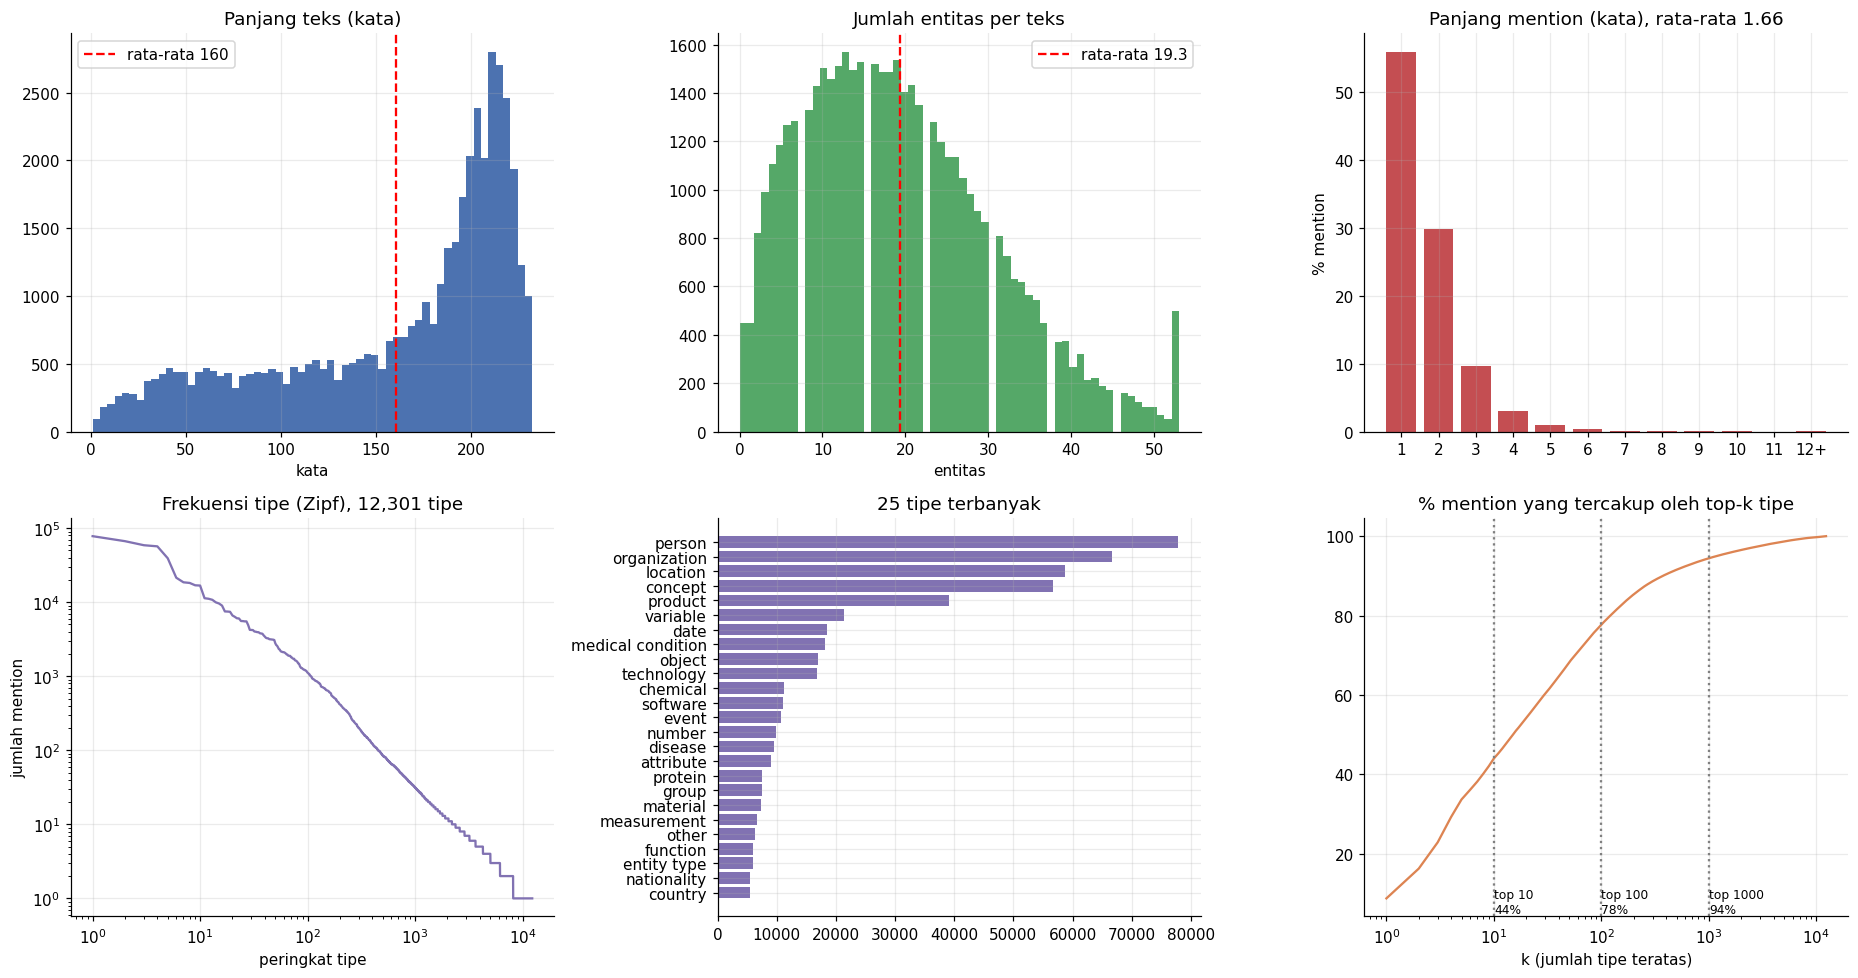

Tipe yang hanya muncul 1 kali: 4,140 dari 12,301 (33.7%) -> distribusi ekor panjang.
Top 10 tipe mencakup 44.0% mention; top 100 mencakup 77.7%.


In [7]:
if PILE_ST is not None:
    st = PILE_ST
    fig, ax = plt.subplots(2, 3, figsize=(17, 9))
    w = st["words"]; ax[0,0].hist(np.clip(w, 0, np.percentile(w, 99)), bins=60, color="#4C72B0")
    ax[0,0].axvline(w.mean(), color="r", ls="--", label=f"rata-rata {w.mean():.0f}"); ax[0,0].legend()
    ax[0,0].set_title("Panjang teks (kata)"); ax[0,0].set_xlabel("kata")
    ne = st["nent"]; ax[0,1].hist(np.clip(ne, 0, np.percentile(ne, 99)), bins=min(60, int(ne.max())+1), color="#55A868")
    ax[0,1].axvline(ne.mean(), color="r", ls="--", label=f"rata-rata {ne.mean():.1f}"); ax[0,1].legend()
    ax[0,1].set_title("Jumlah entitas per teks"); ax[0,1].set_xlabel("entitas")
    ml = st["mlen"]; mx = 12; c = np.bincount(np.clip(ml, 0, mx), minlength=mx+1)[1:]
    ax[0,2].bar(range(1, mx+1), 100*c/c.sum(), color="#C44E52"); ax[0,2].set_xticks(range(1, mx+1))
    ax[0,2].set_xticklabels([str(i) if i < mx else f"{mx}+" for i in range(1, mx+1)])
    ax[0,2].set_title(f"Panjang mention (kata), rata-rata {ml.mean():.2f}"); ax[0,2].set_ylabel("% mention")
    tc = st["types"].most_common(); cnt = np.array([v for _, v in tc])
    ax[1,0].loglog(np.arange(1, len(cnt)+1), cnt, color="#8172B2")
    ax[1,0].set_title(f"Frekuensi tipe (Zipf), {len(cnt):,} tipe"); ax[1,0].set_xlabel("peringkat tipe"); ax[1,0].set_ylabel("jumlah mention")
    top = tc[:25][::-1]; ax[1,1].barh([a[:28] for a, _ in top], [b for _, b in top], color="#8172B2")
    ax[1,1].set_title("25 tipe terbanyak")
    cum = np.cumsum(cnt) / cnt.sum() * 100
    ax[1,2].plot(np.arange(1, len(cum)+1), cum, color="#DD8452"); ax[1,2].set_xscale("log")
    for k in (10, 100, 1000):
        if k <= len(cum): ax[1,2].axvline(k, color="gray", ls=":"); ax[1,2].text(k, 5, f"top {k}\n{cum[k-1]:.0f}%", fontsize=8)
    ax[1,2].set_title("% mention yang tercakup oleh top-k tipe"); ax[1,2].set_xlabel("k (jumlah tipe teratas)")
    plt.show()
    once = sum(1 for v in cnt if v == 1)
    print(f"Tipe yang hanya muncul 1 kali: {once:,} dari {len(cnt):,} ({100*once/len(cnt):.1f}%) -> distribusi ekor panjang.")
    print(f"Top 10 tipe mencakup {cum[min(9,len(cum)-1)]:.1f}% mention; top 100 mencakup {cum[min(99,len(cum)-1)]:.1f}%.")

In [8]:
if PILE_ST is not None:
    st = PILE_ST; ne = max(st["n_ent"], 1)
    print("=== Seberapa lengkap label Pile-NER? (alasan distilasi) ===")
    print(f"Mention yang tumpang tindih dengan mention lain : {st['overlap']:,} ({100*st['overlap']/ne:.2f}%)")
    print(f"Mention yang bersarang (nested) di dalam lainnya : {st['nested']:,} ({100*st['nested']/ne:.2f}%)")
    print(f"Teks tanpa entitas sama sekali                   : {(st['nent']==0).mean()*100:.2f}%")
    print(f"Mention > 400 karakter (dibuang oleh max_ent_length): {st['chars400']:,}")
    print("Jika nested ~0%, itu bukti kuat bahwa GPT-3.5 tidak melabeli entitas bersarang, sehingga model")
    print("belajar bahwa 'former chief financial officer' dan 'chief financial officer' tidak boleh sama-sama mention.")
    print()
    mc = collections.Counter()
    for text, ents in PILE[:20000]:
        for s, e, t, nm in ents: mc[str(nm).lower().strip()] += 1
    print("20 mention paling sering (dari 20 ribu sampel pertama):")
    display(pd.DataFrame(mc.most_common(20), columns=["mention", "jumlah"]))
    random.seed(1)
    display(HTML("<h4>Contoh teks dengan mention ter-highlight (potongan 600 karakter)</h4>" +
        "<br><br>".join(render_chars(t, [x for x in en if x[1] <= 600])[:2500] if len(t) > 0 else "" for t, en in
                        [(t[:600], [x for x in en if x[1] <= 600]) for t, en in random.sample(PILE, 4)])))

=== Seberapa lengkap label Pile-NER? (alasan distilasi) ===
Mention yang tumpang tindih dengan mention lain : 47,553 (5.36%)
Mention yang bersarang (nested) di dalam lainnya : 47,413 (5.34%)
Teks tanpa entitas sama sekali                   : 0.98%
Mention > 400 karakter (dibuang oleh max_ent_length): 0
Jika nested ~0%, itu bukti kuat bahwa GPT-3.5 tidak melabeli entitas bersarang, sehingga model
belajar bahwa 'former chief financial officer' dan 'chief financial officer' tidak boleh sama-sama mention.

20 mention paling sering (dari 20 ribu sampel pertama):


,mention,jumlah
0,patients,965
1,a,679
2,x,629
3,united states,500
4,i,480
5,2,450
6,c,418
7,b,417
8,y,403
9,us,392


## 4. B. Dataset benchmark (13 dataset evaluasi Tabel 1)
Semua split (test + dev + train) digabung, sama seperti `eval_table1.py`.
Tiap dataset dihitung: ukuran, panjang teks, panjang mention, kepadatan entitas, huruf kapital, angka, tumpang tindih/nested, jumlah tipe,
dan **seberapa banyak mention benchmark yang pernah muncul di Pile-NER** (indikasi kebocoran/kemudahan zero-shot).

In [9]:
S, EX, SPLITS = {}, {}, {}
t0 = time.time()
for name in BENCH:
    try:
        recs, ps = [], {}
        for p in data_files(DATA / name):
            r = [parse_record(ex) for ex in read_any(p)]
            r = [x for x in r if x is not None]
            ps[p.stem] = (len(r), sum(len(e) for _, e in r)); recs += r
        if not recs:
            print(f"[{name}] format tidak terbaca"); continue
        S[name] = analyze(recs, ref_set=PILE_SET); SPLITS[name] = ps
        EX[name] = random.Random(0).sample(recs, min(300, len(recs)))
        print(f"[{name}] {len(recs):,} sampel ({time.time()-t0:.0f} dtk)")
        del recs; gc.collect()
    except Exception as ex:
        print(f"[{name}] error: {ex!r}")
BF = pd.DataFrame({n: summ_row(S[n]) for n in S}).T
BF = BF.reindex([n for n in BENCH if n in BF.index])
for c in BF.columns:
    BF[c] = pd.to_numeric(BF[c], errors="coerce")
for c in ("n_sampel", "n_entitas", "n_tipe", "len_max"):
    BF[c] = BF[c].astype(int)

[MultiNERD] 154,144 sampel (4 dtk)
[CoNLL 2003] 20,744 sampel (5 dtk)
[CrossNER_politics] 1,389 sampel (5 dtk)
[CrossNER_AI] 881 sampel (5 dtk)
[CrossNER_literature] 916 sampel (5 dtk)
[CrossNER_science] 1,193 sampel (6 dtk)
[CrossNER_music] 945 sampel (6 dtk)
[ncbi] 7,295 sampel (6 dtk)
[FabNER] 13,681 sampel (7 dtk)
[WikiNeural] 115,907 sampel (10 dtk)
[Ontonotes] 76,714 sampel (13 dtk)
[ACE 2005] 9,330 sampel (13 dtk)
[GENIA_NER] 18,546 sampel (14 dtk)


,n_sampel,n_entitas,kata_per_sampel,ent_per_sampel,ent_per_100_kata,cakupan_kata_%,sampel_tanpa_ent_%,n_tipe
MultiNERD,154144,238014,21.74,1.54,7.10,12.72,0.00,16
CoNLL 2003,20744,35089,14.53,1.69,11.64,16.84,20.49,4
CrossNER_politics,1389,8969,43.50,6.46,14.84,37.74,0.00,9
CrossNER_AI,881,3881,31.43,4.41,14.01,29.76,0.23,14
CrossNER_literature,916,4929,37.60,5.38,14.31,33.02,0.00,12
CrossNER_science,1193,6699,35.81,5.62,15.68,34.34,0.00,17
CrossNER_music,945,6661,41.38,7.05,17.03,39.86,0.00,15
ncbi,7295,6878,25.30,0.94,3.73,8.22,45.83,1
FabNER,13681,64777,25.55,4.73,18.53,24.85,0.00,12
WikiNeural,115907,149011,23.54,1.29,5.46,8.64,20.05,3


Cek terhadap Tabel 1 paper (selisih 0 = identik; selisih entitas wajar kalau cara hitung entitas bersarang berbeda):


,sampel_kita,sampel_paper,entitas_kita,entitas_paper,selisih_sampel,selisih_entitas
MultiNERD,154144,154144,238014,238005,0,9
CoNLL 2003,20744,16493,35089,34761,4251,328
CrossNER_politics,1389,1389,8969,8838,0,131
CrossNER_AI,881,879,3881,3776,2,105
CrossNER_literature,916,916,4929,4749,0,180
CrossNER_science,1193,1193,6699,6318,0,381
CrossNER_music,945,945,6661,6420,0,241
ncbi,7295,3952,6878,6808,3343,70
FabNER,13681,13681,64777,64761,0,16
WikiNeural,115907,92672,149011,149005,23235,6


,dev_sampel,test_sampel,train_sampel
dataset,,,
MultiNERD,10000,10000,134144
CoNLL 2003,3250,3453,14041
CrossNER_politics,540,650,199
CrossNER_AI,350,431,100
CrossNER_literature,400,416,100
CrossNER_science,450,543,200
CrossNER_music,380,465,100
ncbi,923,940,5432
FabNER,2182,2064,9435


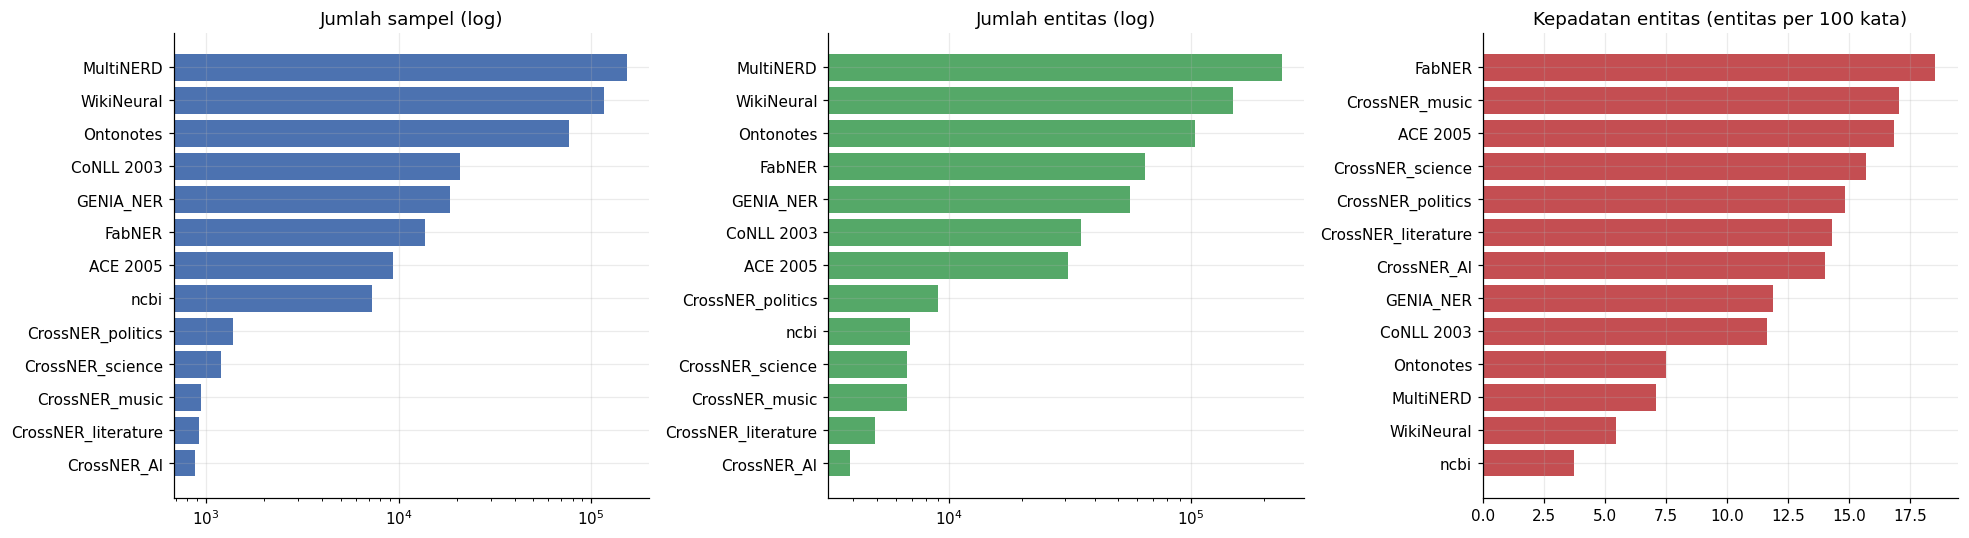

In [10]:
display(BF[["n_sampel","n_entitas","kata_per_sampel","ent_per_sampel","ent_per_100_kata","cakupan_kata_%","sampel_tanpa_ent_%","n_tipe"]])
chk = pd.DataFrame({"sampel_kita": BF.n_sampel, "sampel_paper": PAPER.n_sampel.reindex(BF.index),
                    "entitas_kita": BF.n_entitas, "entitas_paper": PAPER.n_entitas.reindex(BF.index)})
chk["selisih_sampel"] = chk.sampel_kita - chk.sampel_paper
chk["selisih_entitas"] = chk.entitas_kita - chk.entitas_paper
chk = chk.astype(int)
print("Cek terhadap Tabel 1 paper (selisih 0 = identik; selisih entitas wajar kalau cara hitung entitas bersarang berbeda):")
display(chk)
sp = pd.DataFrame({n: {f"{k}_sampel": v[0] for k, v in SPLITS[n].items()} for n in SPLITS}).T
display(sp.fillna(0).astype(int).rename_axis("dataset"))

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
o = BF.sort_values("n_sampel"); ax[0].barh(o.index, o.n_sampel, color="#4C72B0"); ax[0].set_xscale("log"); ax[0].set_title("Jumlah sampel (log)")
o = BF.sort_values("n_entitas"); ax[1].barh(o.index, o.n_entitas, color="#55A868"); ax[1].set_xscale("log"); ax[1].set_title("Jumlah entitas (log)")
o = BF.sort_values("ent_per_100_kata"); ax[2].barh(o.index, o.ent_per_100_kata, color="#C44E52"); ax[2].set_title("Kepadatan entitas (entitas per 100 kata)")
plt.show()

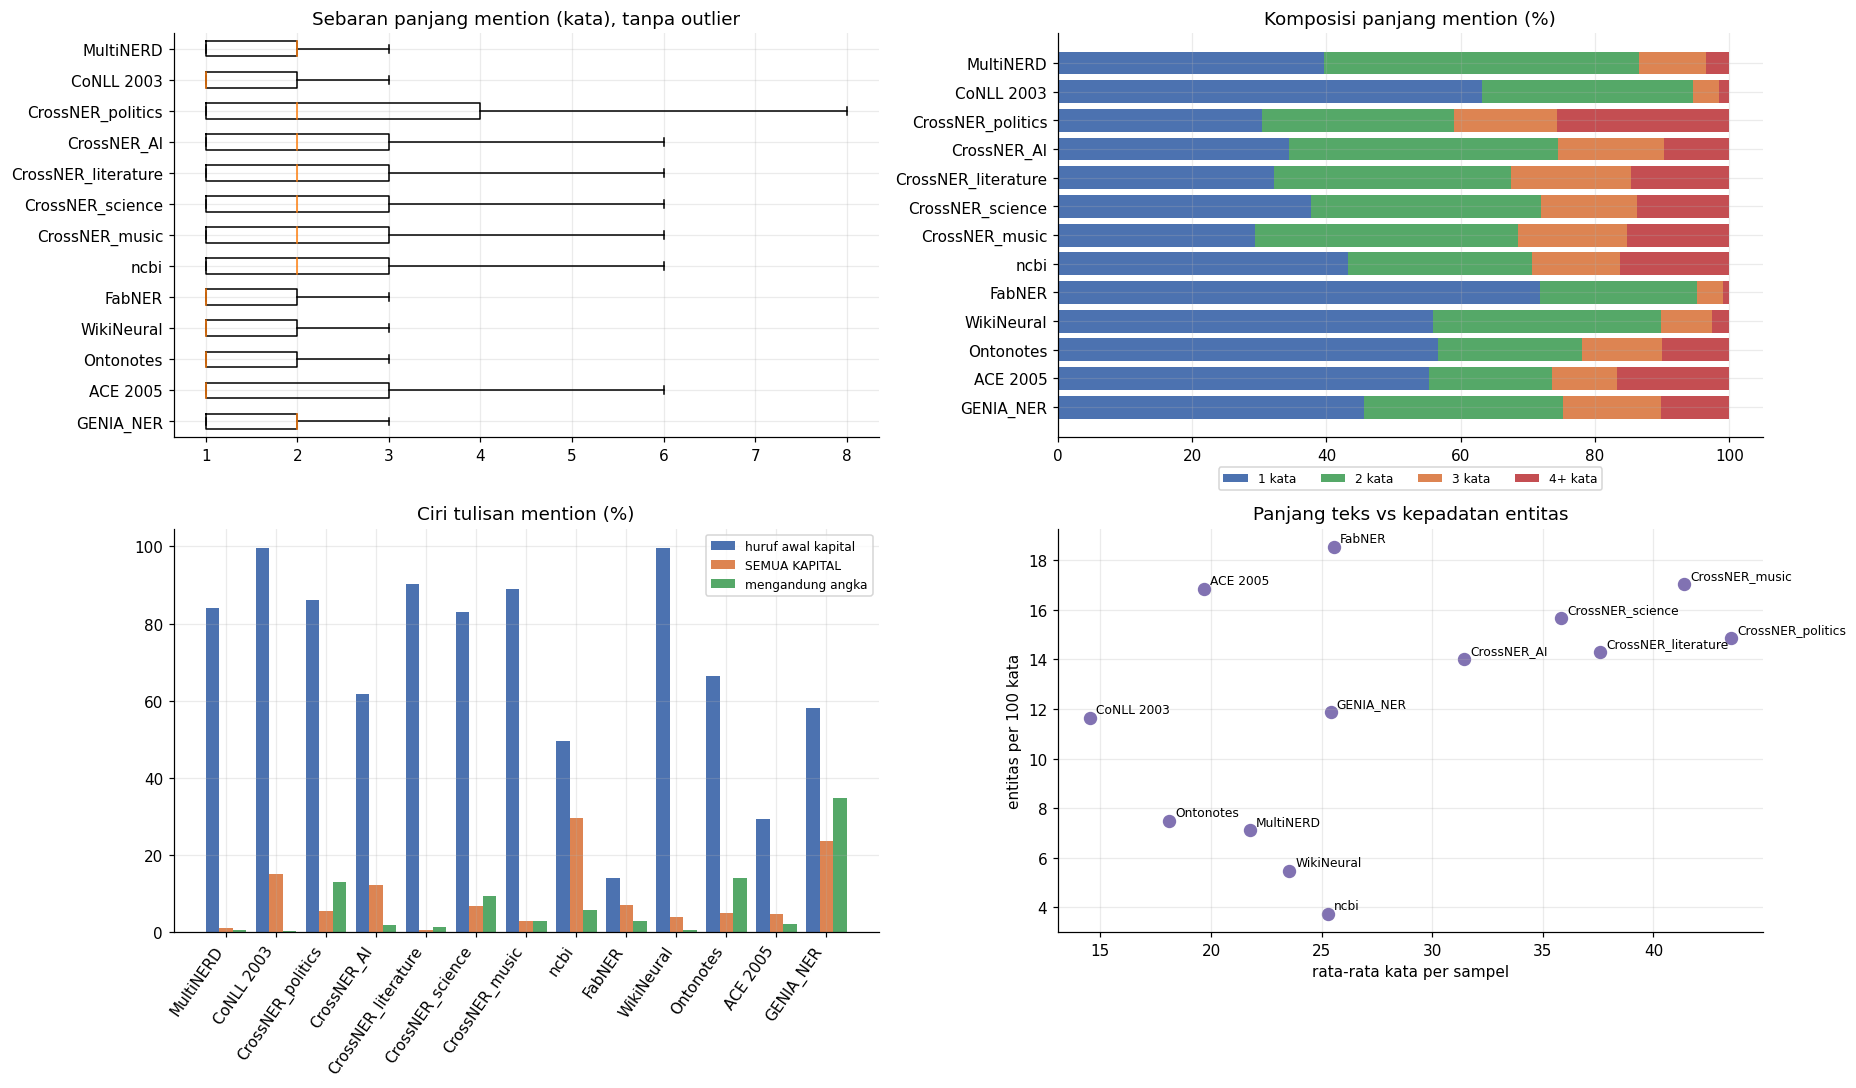

,len_mention_rata,len_median,len_p95,len_max,len=1_%,len>25_%,kapital_awal_%,SEMUA_KAPITAL_%,mengandung_angka_%
MultiNERD,1.79,2.00,3.00,21,39.64,0.00,84.00,1.09,0.72
CoNLL 2003,1.45,1.00,3.00,10,63.19,0.00,99.60,15.18,0.45
CrossNER_politics,2.54,2.00,5.00,16,30.36,0.00,86.01,5.42,13.13
CrossNER_AI,2.12,2.00,5.00,12,34.37,0.00,61.84,12.29,1.80
CrossNER_literature,2.31,2.00,5.00,18,32.12,0.00,90.32,0.75,1.46
CrossNER_science,2.19,2.00,5.00,13,37.69,0.00,83.07,6.75,9.48
CrossNER_music,2.34,2.00,5.00,16,29.33,0.00,88.85,2.97,3.02
ncbi,2.20,2.00,5.00,22,43.14,0.00,49.67,29.57,5.77
FabNER,1.34,1.00,2.00,7,71.79,0.00,14.15,7.22,2.85
WikiNeural,1.58,1.00,3.00,15,55.86,0.00,99.55,4.10,0.73


In [11]:
fig, ax = plt.subplots(2, 2, figsize=(17, 10))
names = list(BF.index)
data = [np.clip(S[n]["mlen"], 0, 15) for n in names]
ax[0,0].boxplot(data, vert=False, showfliers=False, labels=names); ax[0,0].set_title("Sebaran panjang mention (kata), tanpa outlier")
ax[0,0].invert_yaxis()
bins = {"1 kata": lambda m: (m == 1), "2 kata": lambda m: (m == 2), "3 kata": lambda m: (m == 3), "4+ kata": lambda m: (m >= 4)}
left = np.zeros(len(names)); cols = ["#4C72B0", "#55A868", "#DD8452", "#C44E52"]
for (lab, fn), c in zip(bins.items(), cols):
    v = np.array([100 * fn(S[n]["mlen"]).mean() for n in names])
    ax[0,1].barh(names, v, left=left, label=lab, color=c); left += v
ax[0,1].set_title("Komposisi panjang mention (%)"); ax[0,1].legend(ncol=4, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.06)); ax[0,1].invert_yaxis()
x = np.arange(len(names)); wd = 0.27
ax[1,0].bar(x - wd, BF["kapital_awal_%"], wd, label="huruf awal kapital", color="#4C72B0")
ax[1,0].bar(x, BF["SEMUA_KAPITAL_%"], wd, label="SEMUA KAPITAL", color="#DD8452")
ax[1,0].bar(x + wd, BF["mengandung_angka_%"], wd, label="mengandung angka", color="#55A868")
ax[1,0].set_xticks(x); ax[1,0].set_xticklabels(names, rotation=55, ha="right"); ax[1,0].set_title("Ciri tulisan mention (%)"); ax[1,0].legend(fontsize=8)
ax[1,1].scatter(BF["kata_per_sampel"], BF["ent_per_100_kata"], s=60, color="#8172B2")
for n in names: ax[1,1].annotate(n, (BF.loc[n, "kata_per_sampel"], BF.loc[n, "ent_per_100_kata"]), fontsize=8, xytext=(4, 3), textcoords="offset points")
ax[1,1].set_xlabel("rata-rata kata per sampel"); ax[1,1].set_ylabel("entitas per 100 kata"); ax[1,1].set_title("Panjang teks vs kepadatan entitas")
plt.show()
display(BF[["len_mention_rata","len_median","len_p95","len_max","len=1_%","len>25_%","kapital_awal_%","SEMUA_KAPITAL_%","mengandung_angka_%"]])

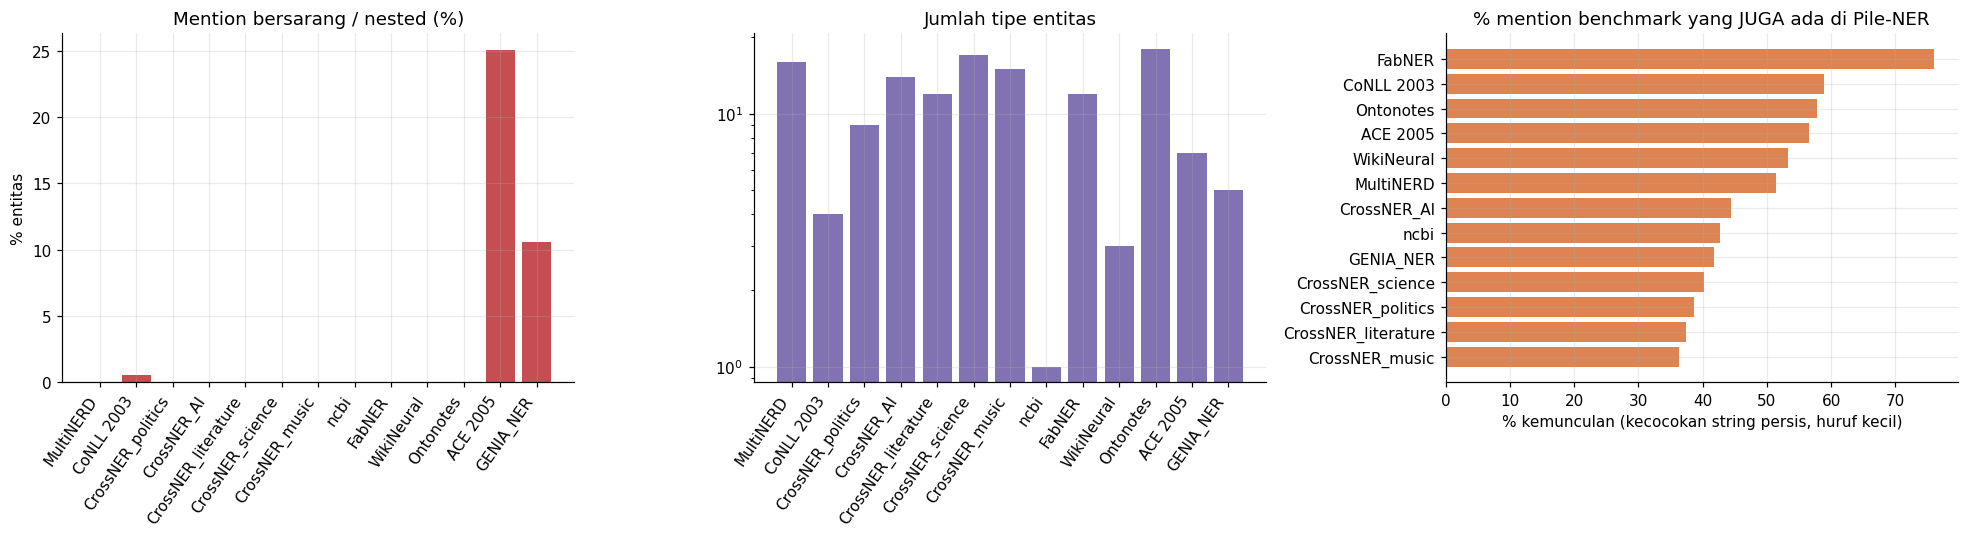

,n_tipe,3_tipe_teratas
dataset,,
MultiNERD,16,location (32%); person (29%); organization (13%)
CoNLL 2003,4,location (30%); person (29%); organization (27%)
CrossNER_politics,9,political party (25%); politician (14%); location (12%)
CrossNER_AI,14,algorithm (11%); product (11%); task (11%)
CrossNER_literature,12,writer (25%); book (17%); else (10%)
CrossNER_science,17,else (16%); scientist (14%); astronomical object (12%)
CrossNER_music,15,musical artist (16%); band (15%); music genre (14%)
ncbi,1,disease (100%)
FabNER,12,concept or principle (33%); material (20%); manufacturing process (16%)


Dataset dengan nested/tumpang tindih (butuh decoding non-flat):  ['ACE 2005', 'GENIA_NER']
Mention > 25 kata (di luar batas span ToMMeR): {'Ontonotes': 0.001, 'ACE 2005': 0.123}


In [12]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
x = np.arange(len(names))
ax[0].bar(x, BF["nested_%"], color="#C44E52"); ax[0].set_xticks(x); ax[0].set_xticklabels(names, rotation=55, ha="right")
ax[0].set_title("Mention bersarang / nested (%)"); ax[0].set_ylabel("% entitas")
ax[1].bar(x, BF["n_tipe"], color="#8172B2"); ax[1].set_xticks(x); ax[1].set_xticklabels(names, rotation=55, ha="right")
ax[1].set_title("Jumlah tipe entitas"); ax[1].set_yscale("log")
if BF["mention_ada_di_PileNER_%"].notna().any():
    o = BF.sort_values("mention_ada_di_PileNER_%")
    ax[2].barh(o.index, o["mention_ada_di_PileNER_%"], color="#DD8452"); ax[2].set_title("% mention benchmark yang JUGA ada di Pile-NER")
    ax[2].set_xlabel("% kemunculan (kecocokan string persis, huruf kecil)")
plt.show()

top = []
for n in names:
    tc = S[n]["types"].most_common(3); tot = max(S[n]["n_ent"], 1)
    top.append({"dataset": n, "n_tipe": len(S[n]["types"]),
                "3_tipe_teratas": "; ".join(f"{a} ({100*b/tot:.0f}%)" for a, b in tc)})
display(pd.DataFrame(top).set_index("dataset"))
print("Dataset dengan nested/tumpang tindih (butuh decoding non-flat): ", [n for n in names if BF.loc[n, "nested_%"] > 1])
print("Mention > 25 kata (di luar batas span ToMMeR):", {n: round(BF.loc[n, "len>25_%"], 3) for n in names if BF.loc[n, "len>25_%"] > 0})

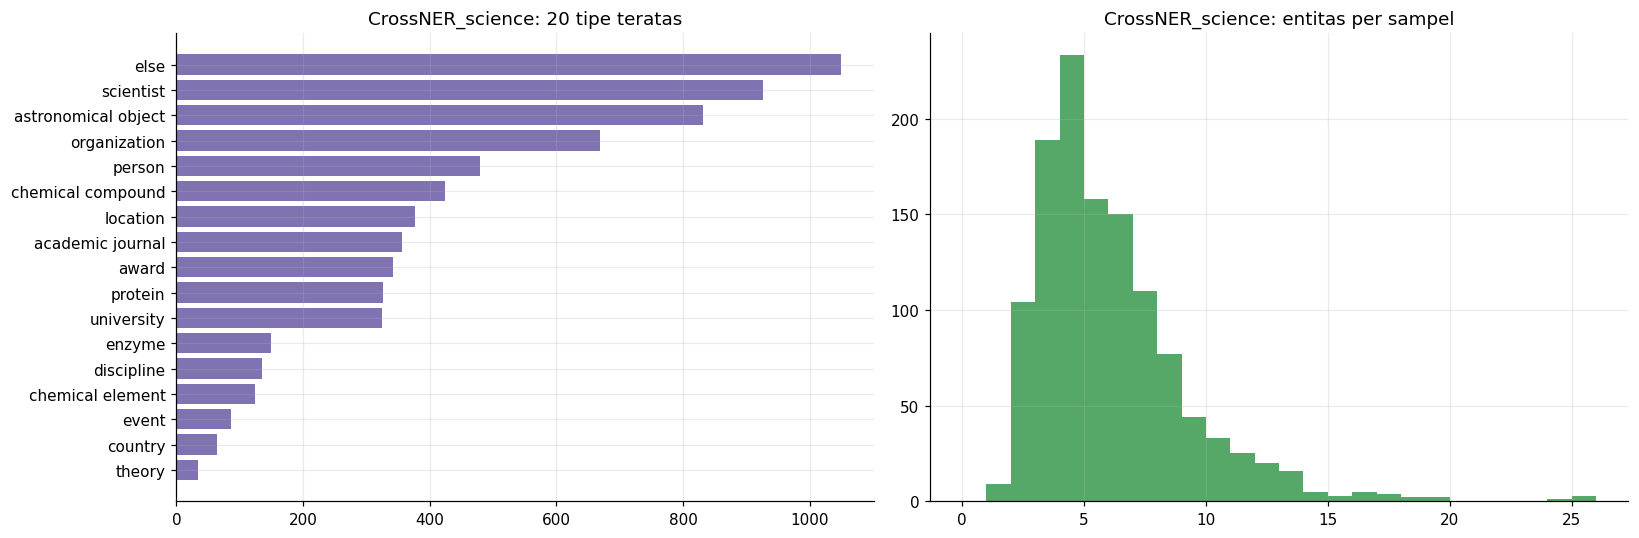

Ganti FOCUS di sel setup untuk melihat dataset lain.


In [13]:
name = FOCUS if FOCUS in S else list(S)[0]
st = S[name]; tc = st["types"].most_common(20)[::-1]
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].barh([a[:30] for a, _ in tc], [b for _, b in tc], color="#8172B2"); ax[0].set_title(f"{name}: 20 tipe teratas")
ax[1].hist(np.clip(st["nent"], 0, 25), bins=range(0, 27), color="#55A868"); ax[1].set_title(f"{name}: entitas per sampel")
plt.show()
display(HTML(f"<h4>{html.escape(name)}: contoh kalimat dengan gold ter-highlight</h4>" +
    "<br><br>".join(render_chars(t, e) for t, e in EX[name][:6])))
print("Ganti FOCUS di sel setup untuk melihat dataset lain.")

## 5. Pile-NER vs benchmark
Perbedaan "definisi entitas" antar dataset adalah alasan utama **precision terhadap gold rendah** (ToMMeR menandai semua mention, benchmark hanya melabeli tipe tertentu).

,ent_per_100_kata,cakupan_kata_%,len_mention_rata,kapital_awal_%,mengandung_angka_%,nested_%,n_tipe
ncbi,3.73,8.22,2.20,49.67,5.77,0.00,1.00
WikiNeural,5.46,8.64,1.58,99.55,0.73,0.00,3.00
MultiNERD,7.10,12.72,1.79,84.00,0.72,0.00,16.00
Ontonotes,7.50,13.70,1.83,66.44,13.99,0.00,18.00
CoNLL 2003,11.64,16.84,1.45,99.60,0.45,0.56,4.00
GENIA_NER,11.89,23.43,1.97,58.04,34.93,10.58,5.00
== PILE-NER (training) ==,12.07,20.07,1.66,46.18,8.02,5.34,"12,301.00"
CrossNER_AI,14.01,29.76,2.12,61.84,1.80,0.00,14.00
CrossNER_literature,14.31,33.02,2.31,90.32,1.46,0.00,12.00
CrossNER_politics,14.84,37.74,2.54,86.01,13.13,0.00,9.00


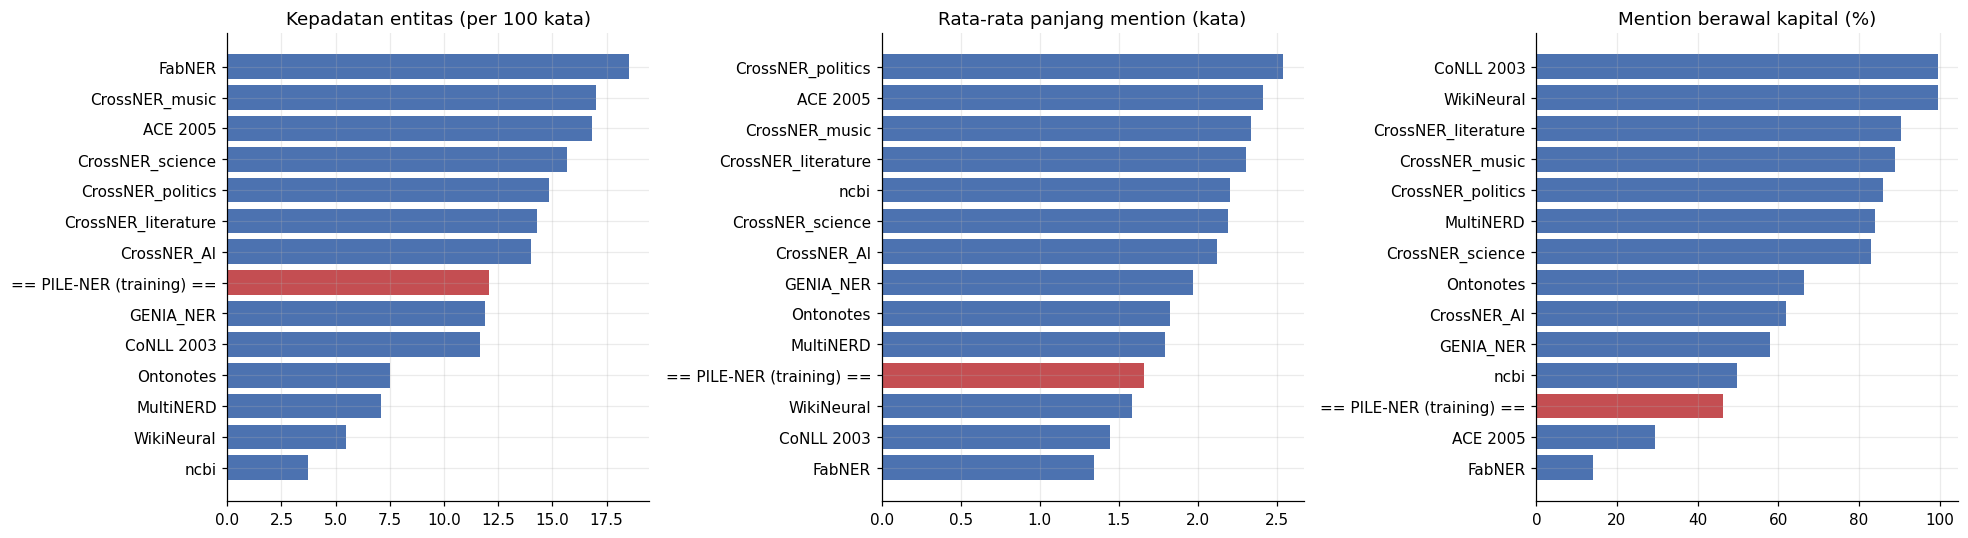

Baca: kalau Pile-NER jauh lebih rapat/lebih beragam daripada benchmark, wajar kalau ToMMeR menandai lebih banyak span
daripada gold (recall tinggi, precision gold rendah).


In [14]:
if PILE_ST is not None:
    pr = summ_row(PILE_ST)
    cols = ["ent_per_100_kata", "cakupan_kata_%", "len_mention_rata", "kapital_awal_%", "mengandung_angka_%", "nested_%", "n_tipe"]
    comp = BF[cols].copy(); comp.loc["== PILE-NER (training) =="] = [pr[c] for c in cols]
    display(comp.sort_values("ent_per_100_kata"))
    fig, ax = plt.subplots(1, 3, figsize=(18, 5))
    for a, c, t in zip(ax, ["ent_per_100_kata", "len_mention_rata", "kapital_awal_%"],
                       ["Kepadatan entitas (per 100 kata)", "Rata-rata panjang mention (kata)", "Mention berawal kapital (%)"]):
        v = comp[c].sort_values(); colr = ["#C44E52" if "PILE" in i else "#4C72B0" for i in v.index]
        a.barh(v.index, v.values, color=colr); a.set_title(t)
    plt.show()
    print("Baca: kalau Pile-NER jauh lebih rapat/lebih beragam daripada benchmark, wajar kalau ToMMeR menandai lebih banyak span")
    print("daripada gold (recall tinggi, precision gold rendah).")
else:
    print("Pile-NER tidak termuat.")

## 6. C. Kurva training
Membaca log tensorboard dari semua `xpm-workspace*`. Fase 0 ada di folder `runs/`, distilasi di `lightning_logs/`.
Kolom `step_per_dtk` memperlihatkan efek masalah throttling CPU di awal (0,2 vs belasan step/detik).

In [15]:
try:
    from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
    TB = True
except Exception as ex:
    TB = False; print("tensorboard tidak tersedia:", ex)

def collect_logs():
    seen, runs = set(), []
    for f in sorted(REPO.glob("xpm-workspace*/jobs/**/events.out.tfevents*")):
        rp = f.resolve()
        if rp in seen: continue
        seen.add(rp)
        parts = f.relative_to(REPO).parts
        phase = "distilasi" if "lightning_logs" in parts else ("fase0" if "runs" in parts else "?")
        m = re.search(r"_L(\d+)", "/".join(parts)); layer = int(m.group(1)) if m else None
        runs.append((parts[0], phase, layer, f))
    return runs

RUNS = {}
if TB:
    rows = []
    for ws, phase, layer, f in collect_logs():
        try:
            ea = EventAccumulator(str(f), size_guidance={"scalars": 0}); ea.Reload()
            tags = ea.Tags()["scalars"]
            if "lr-AdamW" not in tags: continue
            lr = ea.Scalars("lr-AdamW")
            if len(lr) < 20: continue
            key = f"{ws}|{phase}|L{layer}"
            data = {t: [(e.step, e.value, e.wall_time) for e in ea.Scalars(t)] for t in tags}
            sp = np.diff([e.wall_time for e in lr]); st_ = np.diff([e.step for e in lr])
            rate = float(np.median(st_ / np.maximum(sp, 1e-9)))
            vf = data.get("val/f1", [])
            rows.append({"run": key, "step_terakhir": lr[-1].step, "epoch_terakhir": data["epoch"][-1][1] if "epoch" in data else np.nan,
                         "durasi_menit": (lr[-1].wall_time - lr[0].wall_time) / 60, "step_per_dtk_median": rate,
                         "val_f1_terbaik": max((v for _, v, _ in vf), default=np.nan),
                         "val_f1_akhir": vf[-1][1] if vf else np.nan})
            RUNS[key] = data
        except Exception as ex:
            print("gagal baca", f.name, repr(ex))
    if rows:
        display(pd.DataFrame(rows).set_index("run"))
    else:
        print("Belum ada log training yang terbaca.")

tensorboard tidak tersedia: No module named 'tensorboard'


In [16]:
def ema(y, a=0.98):
    out, m = [], None
    for v in y:
        m = v if m is None else a * m + (1 - a) * v
        out.append(m)
    return out

if RUNS:
    panels = [("train/loss_step", "Train loss (EMA)"), ("val/f1", "Validasi F1"), ("val/recall", "Validasi recall"),
              ("val/precision", "Validasi precision"), ("lr-AdamW", "Learning rate"), ("train/loss_epoch", "Train loss per epoch")]
    fig, ax = plt.subplots(2, 3, figsize=(18, 9)); ax = ax.ravel()
    for a, (tag, title) in zip(ax, panels):
        for key, data in RUNS.items():
            if tag in data and len(data[tag]) > 1:
                x = [s for s, _, _ in data[tag]]; y = [v for _, v, _ in data[tag]]
                a.plot(x, ema(y) if tag == "train/loss_step" else y, label=key, lw=1.2)
        a.set_title(title); a.set_xlabel("step")
        if tag == "lr-AdamW": a.set_yscale("log")
    ax[0].legend(fontsize=7)
    plt.show()
    print("Catatan: 'val/*' dihitung pada subset validasi (val_limit=1000), jadi bukan angka benchmark.")
    print("Run dengan step_per_dtk ~0.2 adalah run yang kena throttle CPU (thread berlebihan) sebelum perbaikan OMP_NUM_THREADS.")

## 7. D. Hasil eksperimen (evaluasi zero-shot 13 benchmark)
Semua file `results_*.json` ditemukan otomatis. Tambahkan model baru dengan meletakkan file hasilnya di `~/llm2ner` dan (opsional) menambah `LABELS` dan `META` di sel setup.
Angka recall/precision/F1 dalam **persen**. Precision terhadap gold memang rendah karena ToMMeR menandai lebih banyak span daripada yang dilabeli benchmark.

In [17]:
def load_results():
    recs = []
    for f in sorted(REPO.glob("results_*.json")):
        label = LABELS.get(f.stem, f.stem)
        try:
            d = json.load(open(f))
        except Exception as ex:
            print("gagal baca", f.name, ex); continue
        for k, m in d.items():
            if "/" not in k: continue
            dec, ds = k.split("/", 1)
            recs.append(dict(model=label, file=f.stem, dataset=ds, decoding=dec,
                             recall=100 * m.get("recall", np.nan), precision=100 * m.get("precision", np.nan),
                             f1=100 * m.get("f1", np.nan), total=m.get("total", np.nan), n_samples=m.get("n_samples", np.nan)))
    return pd.DataFrame(recs)

R = load_results()
if R.empty:
    print("Belum ada results_*.json di", REPO)
else:
    print("Model ditemukan:", sorted(R.model.unique()))
    print("Dataset per model:", R.groupby("model").dataset.nunique().to_dict())

def pv(metric, dec):
    t = R[R.decoding == dec].pivot(index="dataset", columns="model", values=metric)
    return t.reindex([d for d in BENCH if d in t.index])

def with_paper(tab, metric, dec):
    key = {"recall": "R", "precision": "P", "f1": "F1"}[metric] + ("_thr" if dec == "threshold" else "_gr")
    out = tab.copy(); out.insert(0, "PAPER Tabel 1", PAPER[key].reindex(out.index)); return out

if not R.empty:
    for dec in ("threshold", "greedy"):
        for metric in ("recall", "precision", "f1"):
            t = with_paper(pv(metric, dec), metric, dec)
            t.loc["RATA-RATA (macro)"] = t.mean()
            print(f"\n### {metric.upper()} - decoding {dec}")
            display(t)

Model ditemukan: ['Mine L5 (tanpa distilasi)', 'Mine L5 + distilasi', 'Rilis L6 (distilasi)']
Dataset per model: {'Mine L5 (tanpa distilasi)': 13, 'Mine L5 + distilasi': 13, 'Rilis L6 (distilasi)': 13}

### RECALL - decoding threshold


model,PAPER Tabel 1,Mine L5 (tanpa distilasi),Mine L5 + distilasi,Rilis L6 (distilasi)
dataset,,,,
MultiNERD,98.60,98.86,99.17,98.58
CoNLL 2003,94.80,94.49,97.32,94.81
CrossNER_politics,97.00,97.53,97.55,97.02
CrossNER_AI,97.00,97.62,97.96,97.06
CrossNER_literature,94.40,94.83,95.00,94.43
CrossNER_science,95.70,96.58,96.71,95.68
CrossNER_music,95.50,96.84,97.29,95.49
ncbi,91.90,93.75,95.26,91.97
FabNER,73.60,77.57,79.52,73.65



### PRECISION - decoding threshold


model,PAPER Tabel 1,Mine L5 (tanpa distilasi),Mine L5 + distilasi,Rilis L6 (distilasi)
dataset,,,,
MultiNERD,21.70,18.69,17.68,21.63
CoNLL 2003,33.60,28.29,24.99,33.53
CrossNER_politics,32.40,26.68,25.29,32.31
CrossNER_AI,35.00,29.34,28.31,35.04
CrossNER_literature,40.30,31.93,30.68,40.21
CrossNER_science,38.20,32.36,31.05,38.12
CrossNER_music,44.10,36.00,34.70,44.00
ncbi,12.70,11.11,10.18,12.64
FabNER,30.10,28.12,27.17,30.11



### F1 - decoding threshold


model,PAPER Tabel 1,Mine L5 (tanpa distilasi),Mine L5 + distilasi,Rilis L6 (distilasi)
dataset,,,,
MultiNERD,35.50,31.44,30.01,35.48
CoNLL 2003,49.60,43.54,39.77,49.54
CrossNER_politics,48.60,41.90,40.16,48.48
CrossNER_AI,51.50,45.12,43.93,51.49
CrossNER_literature,56.50,47.78,46.38,56.40
CrossNER_science,54.60,48.47,47.00,54.52
CrossNER_music,60.30,52.49,51.15,60.24
ncbi,22.20,19.86,18.40,22.23
FabNER,42.80,41.28,40.50,42.75


... (2 outputs left out)


### PRECISION - decoding greedy


model,PAPER Tabel 1,Mine L5 (tanpa distilasi),Mine L5 + distilasi,Rilis L6 (distilasi)
dataset,,,,
MultiNERD,30.00,28.84,27.92,29.96
CoNLL 2003,44.70,42.26,39.80,44.66
CrossNER_politics,54.50,46.38,44.65,54.46
CrossNER_AI,51.20,49.26,48.23,51.08
CrossNER_literature,56.60,53.14,51.61,56.56
CrossNER_science,55.10,52.42,51.07,55.17
CrossNER_music,61.70,58.35,57.06,61.77
ncbi,17.10,16.00,15.11,17.14
FabNER,39.70,39.69,39.20,39.66



### F1 - decoding greedy


model,PAPER Tabel 1,Mine L5 (tanpa distilasi),Mine L5 + distilasi,Rilis L6 (distilasi)
dataset,,,,
MultiNERD,45.50,44.18,43.05,45.44
CoNLL 2003,58.90,57.00,55.10,58.88
CrossNER_politics,66.50,58.72,56.93,66.14
CrossNER_AI,64.50,62.88,61.97,64.40
CrossNER_literature,68.30,65.53,64.10,68.20
CrossNER_science,67.10,64.92,63.83,67.22
CrossNER_music,72.10,69.48,68.46,72.17
ncbi,27.20,25.82,24.54,27.22
FabNER,43.90,44.78,44.68,43.84


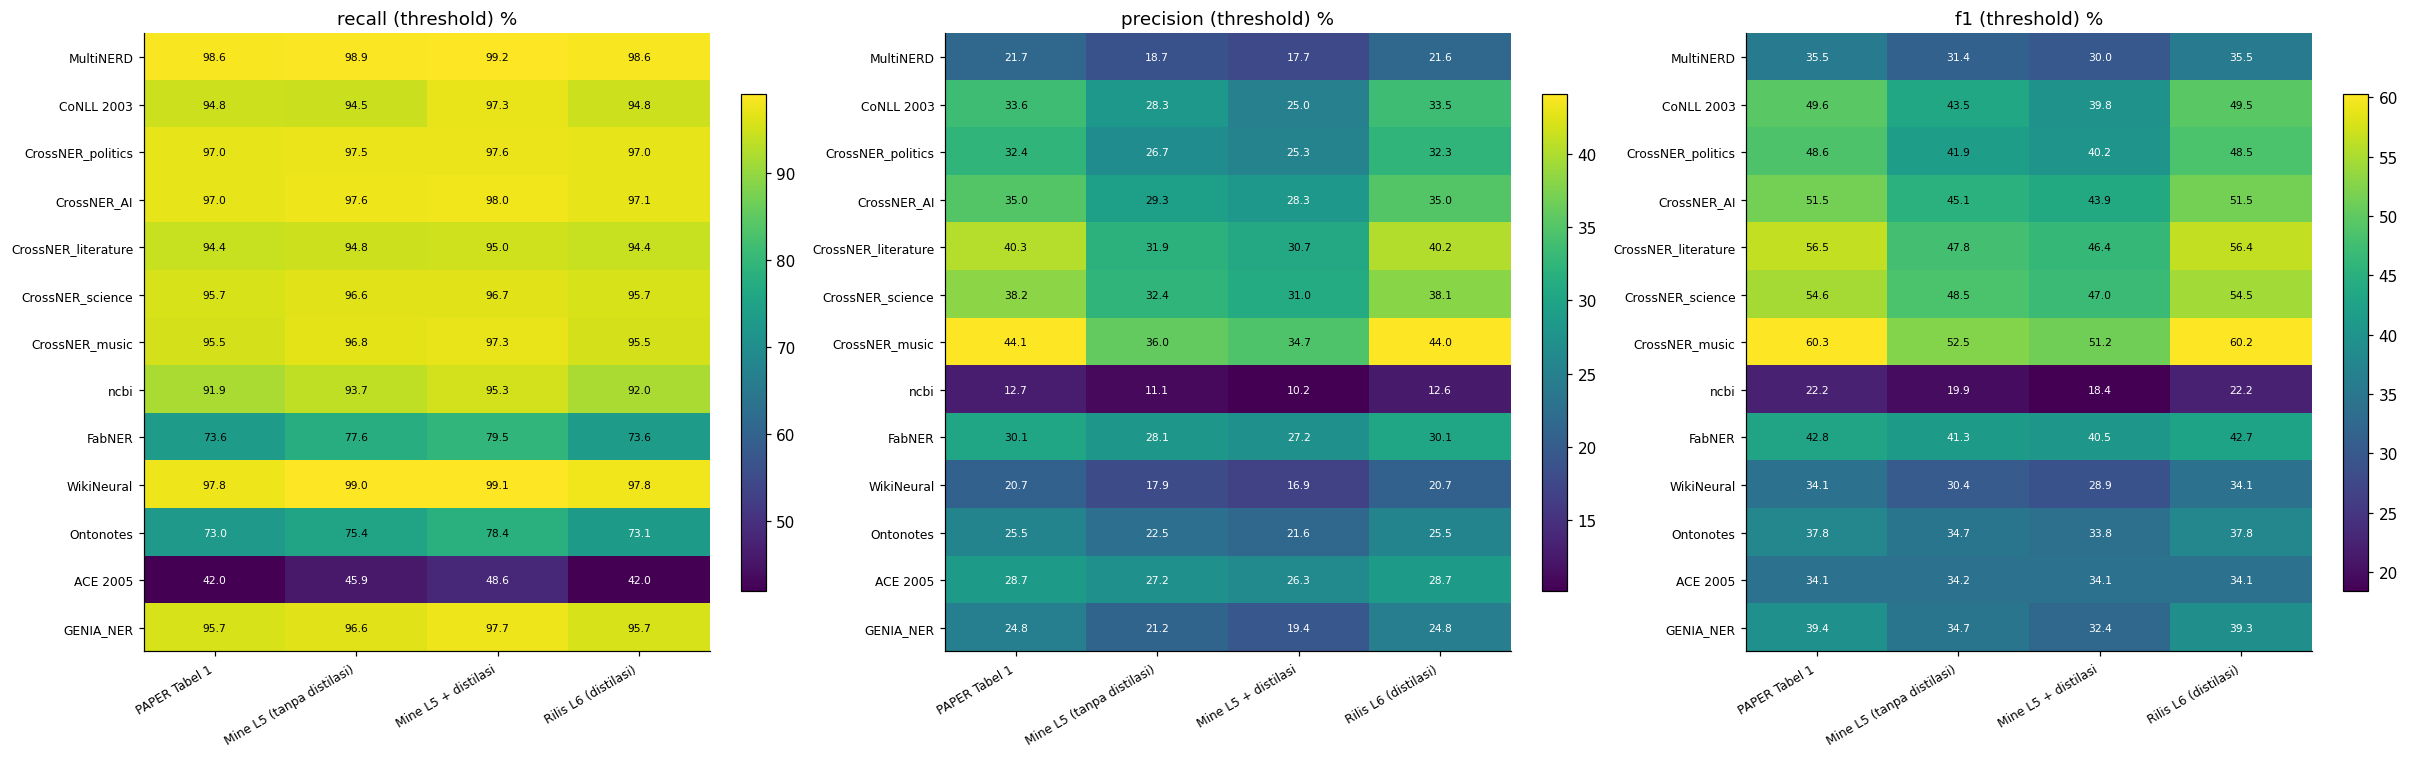

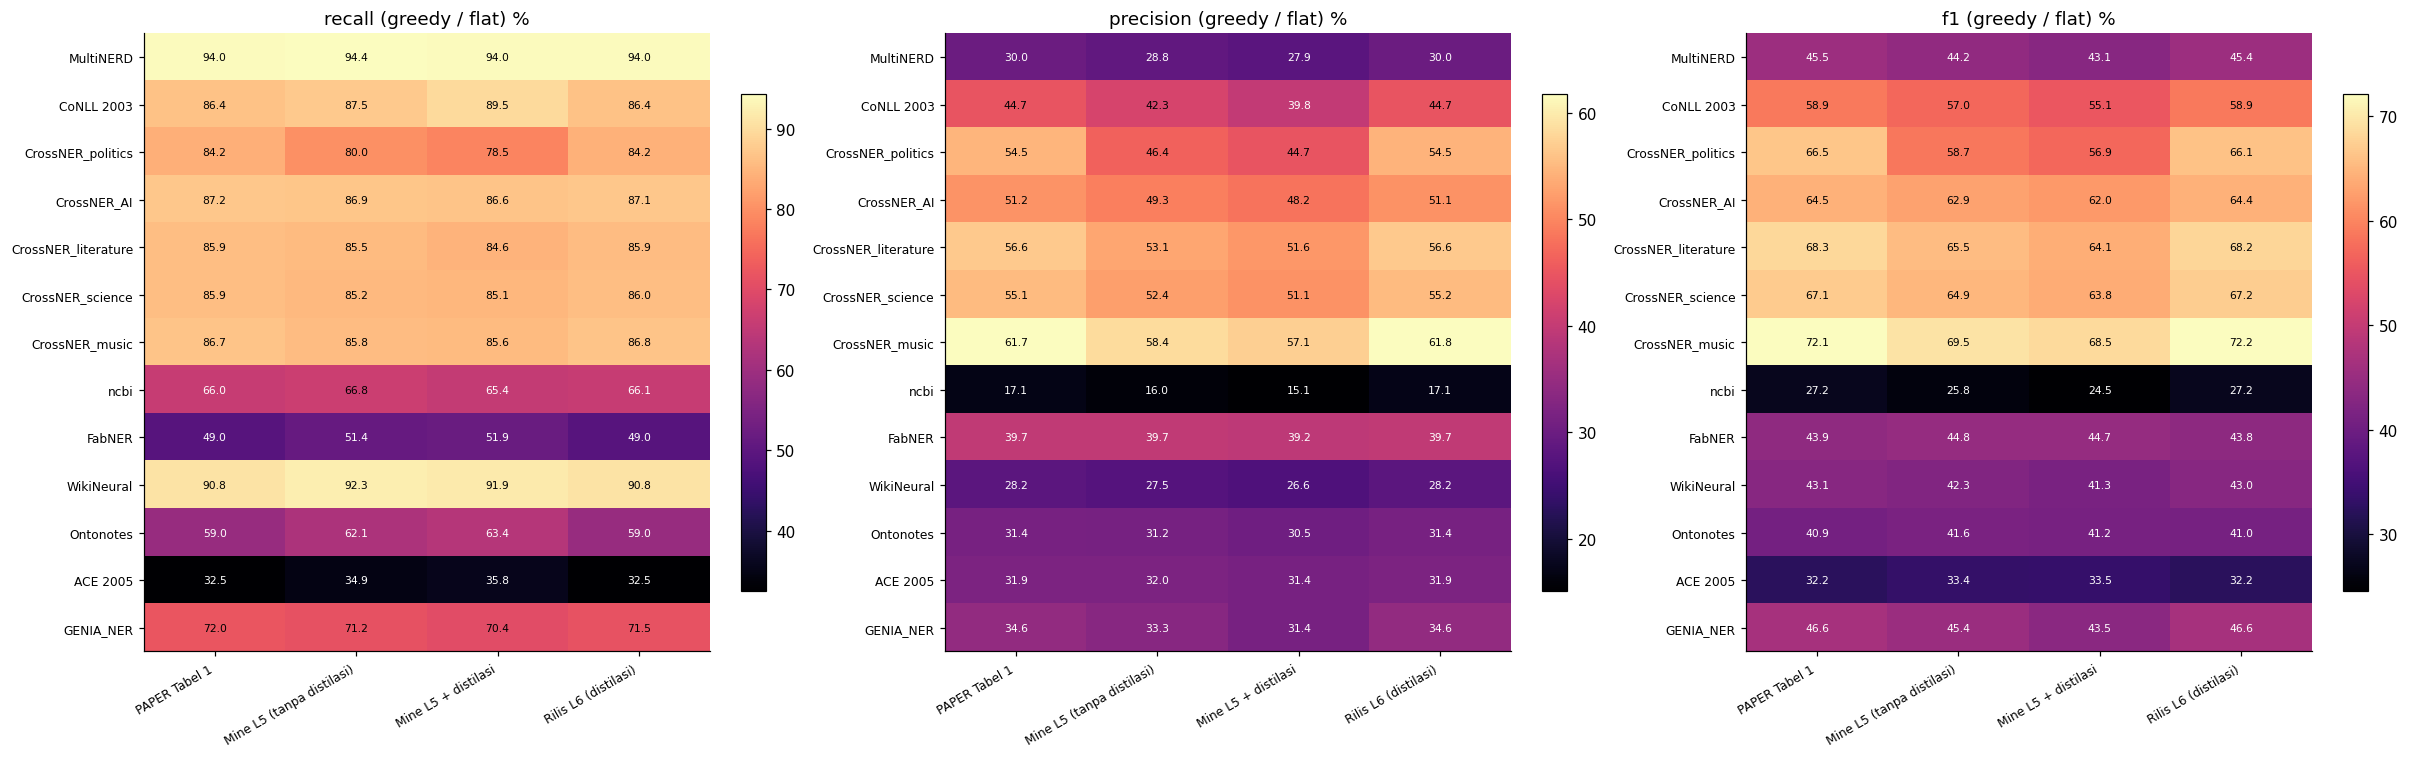

In [18]:
def heat(tab, title, cmap="viridis", fmt="{:.1f}", ax=None):
    ax = ax or plt.gca()
    v = tab.values.astype(float)
    im = ax.imshow(v, aspect="auto", cmap=cmap)
    ax.set_xticks(range(tab.shape[1])); ax.set_xticklabels(tab.columns, rotation=30, ha="right", fontsize=8)
    ax.set_yticks(range(tab.shape[0])); ax.set_yticklabels(tab.index, fontsize=8)
    lo, hi = np.nanmin(v), np.nanmax(v)
    for i in range(v.shape[0]):
        for j in range(v.shape[1]):
            if not np.isnan(v[i, j]):
                ax.text(j, i, fmt.format(v[i, j]), ha="center", va="center", fontsize=7,
                        color="white" if (v[i, j] - lo) / max(hi - lo, 1e-9) < 0.55 else "black")
    ax.set_title(title); ax.grid(False); plt.colorbar(im, ax=ax, fraction=0.04)

if not R.empty:
    fig, ax = plt.subplots(1, 3, figsize=(22, 7))
    for a, metric in zip(ax, ("recall", "precision", "f1")):
        heat(with_paper(pv(metric, "threshold"), metric, "threshold"), f"{metric} (threshold) %", ax=a)
    plt.show()
    fig, ax = plt.subplots(1, 3, figsize=(22, 7))
    for a, metric in zip(ax, ("recall", "precision", "f1")):
        heat(with_paper(pv(metric, "greedy"), metric, "greedy"), f"{metric} (greedy / flat) %", ax=a, cmap="magma")
    plt.show()

Rata-rata paper (macro): threshold R/P/F1 = [88.2, 29.8, 43.6] | greedy = [75.4, 41.3, 52.1]


n_dataset  recall_macro  recall_berbobot  precision_macro  f1_macro
model                     decoding                                                                      
Mine L5 (tanpa distilasi) greedy            13         75.69            79.94            39.25     50.46
                          threshold         13         89.62            90.75            25.49     38.91
Mine L5 + distilasi       greedy            13         75.60            80.00            38.05     49.39
                          threshold         13         90.73            91.84            24.17     37.43
Rilis L6 (distilasi)      greedy            13         75.33            78.76            41.27     52.02
                          threshold         13         88.25            89.43            29.79     43.58

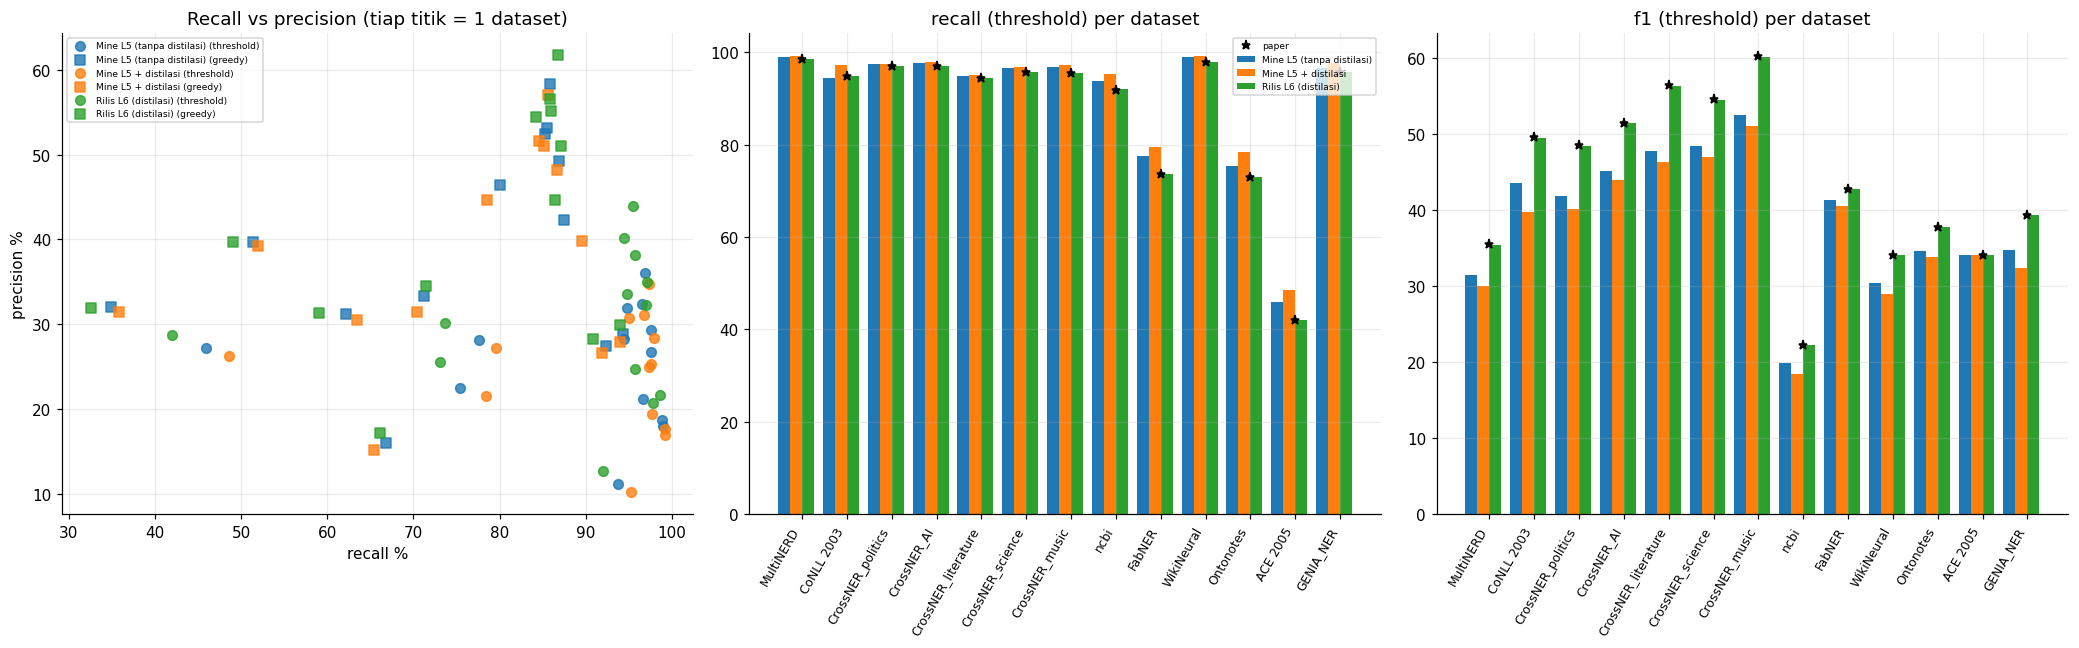

In [19]:
if not R.empty:
    # rata-rata macro + recall berbobot jumlah entitas (seperti baris "Aggregated" di paper)
    rows = []
    for (model, dec), g in R.groupby(["model", "decoding"]):
        g = g[g.dataset.isin(BENCH)]
        wr = np.average(g.recall, weights=g.total) if g.total.notna().all() and g.total.sum() > 0 else np.nan
        rows.append({"model": model, "decoding": dec, "n_dataset": g.dataset.nunique(),
                     "recall_macro": g.recall.mean(), "recall_berbobot": wr,
                     "precision_macro": g.precision.mean(), "f1_macro": g.f1.mean()})
    SUM = pd.DataFrame(rows).set_index(["model", "decoding"]).sort_index()
    pap = {"threshold": (PAPER.R_thr.mean(), PAPER.P_thr.mean(), PAPER.F1_thr.mean()), "greedy": (PAPER.R_gr.mean(), PAPER.P_gr.mean(), PAPER.F1_gr.mean())}
    print("Rata-rata paper (macro): threshold R/P/F1 =", [round(x, 1) for x in pap["threshold"]], "| greedy =", [round(x, 1) for x in pap["greedy"]])
    display(SUM)

    fig, ax = plt.subplots(1, 3, figsize=(19, 6))
    colors = plt.cm.tab10(np.linspace(0, 1, 10))
    for i, model in enumerate(sorted(R.model.unique())):
        for dec, mk in (("threshold", "o"), ("greedy", "s")):
            g = R[(R.model == model) & (R.decoding == dec) & R.dataset.isin(BENCH)]
            ax[0].scatter(g.recall, g.precision, marker=mk, color=colors[i % 10], s=40, alpha=0.8,
                          label=f"{model} ({dec})" if True else None)
    ax[0].set_xlabel("recall %"); ax[0].set_ylabel("precision %"); ax[0].set_title("Recall vs precision (tiap titik = 1 dataset)")
    ax[0].legend(fontsize=6)
    for a, metric in zip(ax[1:], ("recall", "f1")):
        t = pv(metric, "threshold"); g = pv(metric, "greedy")
        x = np.arange(len(t.index)); k = len(t.columns); w = 0.8 / max(k, 1)
        for j, c in enumerate(t.columns):
            a.bar(x + j * w, t[c].values, w, label=c, color=colors[j % 10])
        a.plot(x + 0.4, PAPER["R_thr" if metric == "recall" else "F1_thr"].reindex(t.index).values, "k*", label="paper")
        a.set_xticks(x + 0.4); a.set_xticklabels(t.index, rotation=60, ha="right", fontsize=8); a.set_title(f"{metric} (threshold) per dataset")
    ax[1].legend(fontsize=6)
    plt.show()

In [20]:
if not R.empty:
    print("### Selisih terhadap angka paper (poin persen). Positif = lebih tinggi dari paper.")
    for dec in ("threshold", "greedy"):
        out = {}
        for metric in ("recall", "precision"):
            t = pv(metric, dec); key = ("R" if metric == "recall" else "P") + ("_thr" if dec == "threshold" else "_gr")
            for c in t.columns:
                out[f"{c} | {metric[0].upper()}"] = t[c] - PAPER[key].reindex(t.index)
        d = pd.DataFrame(out); d.loc["RATA-RATA"] = d.mean()
        print(f"\nDecoding {dec}"); display(d)

### Selisih terhadap angka paper (poin persen). Positif = lebih tinggi dari paper.

Decoding threshold


,Mine L5 (tanpa distilasi) | R,Mine L5 + distilasi | R,Rilis L6 (distilasi) | R,Mine L5 (tanpa distilasi) | P,Mine L5 + distilasi | P,Rilis L6 (distilasi) | P
dataset,,,,,,
MultiNERD,0.26,0.57,-0.02,-3.01,-4.02,-0.07
CoNLL 2003,-0.31,2.52,0.01,-5.31,-8.61,-0.07
CrossNER_politics,0.53,0.55,0.02,-5.72,-7.11,-0.09
CrossNER_AI,0.62,0.96,0.06,-5.66,-6.69,0.04
CrossNER_literature,0.43,0.60,0.03,-8.37,-9.62,-0.09
CrossNER_science,0.88,1.01,-0.02,-5.84,-7.15,-0.08
CrossNER_music,1.34,1.79,-0.01,-8.10,-9.40,-0.10
ncbi,1.85,3.36,0.07,-1.59,-2.52,-0.06
FabNER,3.97,5.92,0.05,-1.98,-2.93,0.01



Decoding greedy


,Mine L5 (tanpa distilasi) | R,Mine L5 + distilasi | R,Rilis L6 (distilasi) | R,Mine L5 (tanpa distilasi) | P,Mine L5 + distilasi | P,Rilis L6 (distilasi) | P
dataset,,,,,,
MultiNERD,0.36,-0.01,-0.02,-1.16,-2.08,-0.04
CoNLL 2003,1.12,3.15,-0.01,-2.44,-4.90,-0.04
CrossNER_politics,-4.19,-5.69,0.02,-8.12,-9.85,-0.04
CrossNER_AI,-0.28,-0.57,-0.09,-1.94,-2.97,-0.12
CrossNER_literature,-0.45,-1.33,-0.03,-3.46,-4.99,-0.04
CrossNER_science,-0.66,-0.80,0.08,-2.68,-4.03,0.07
CrossNER_music,-0.86,-1.14,0.07,-3.35,-4.64,0.07
ncbi,0.78,-0.58,0.07,-1.10,-1.99,0.04
FabNER,2.36,2.93,0.02,-0.01,-0.50,-0.04


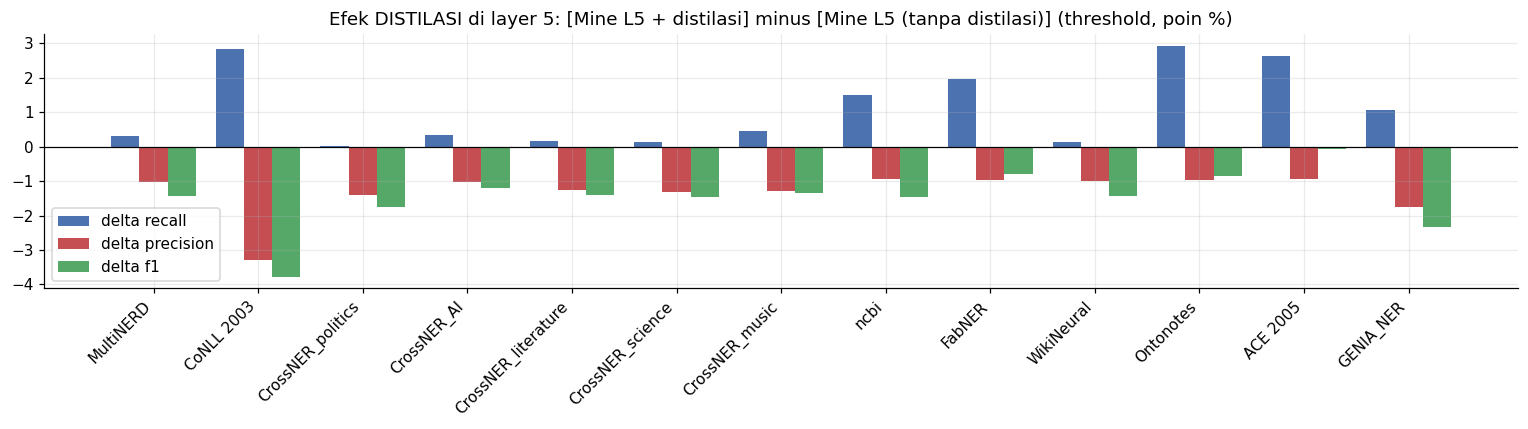

Rata-rata delta: recall +1.11 | precision -1.32 | F1 -1.48 | precision naik di 0/13 dataset


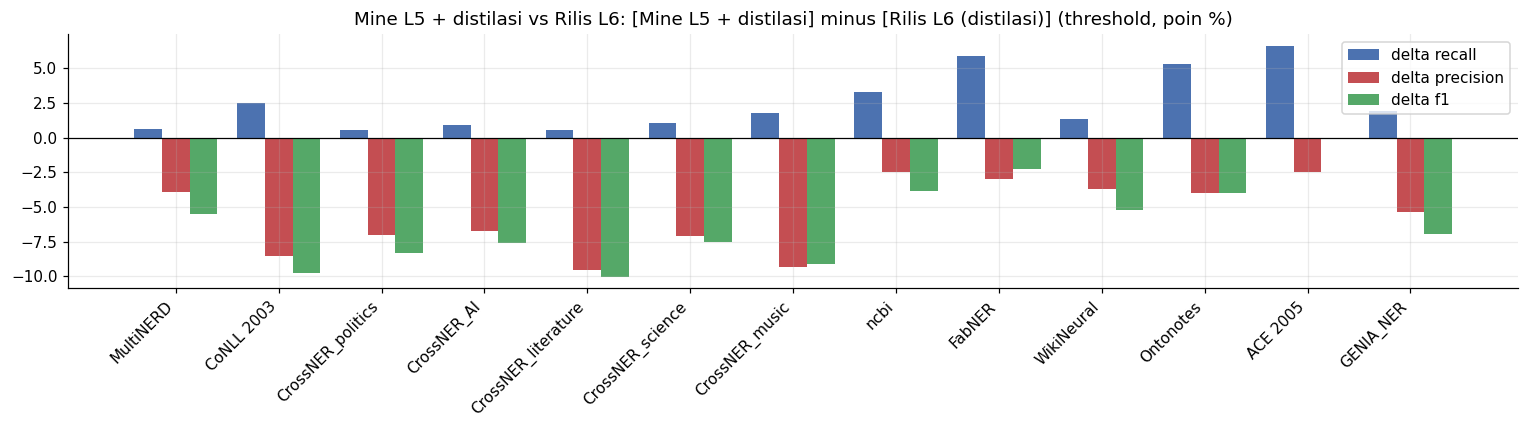

Rata-rata delta: recall +2.48 | precision -5.62 | F1 -6.15 | precision naik di 0/13 dataset


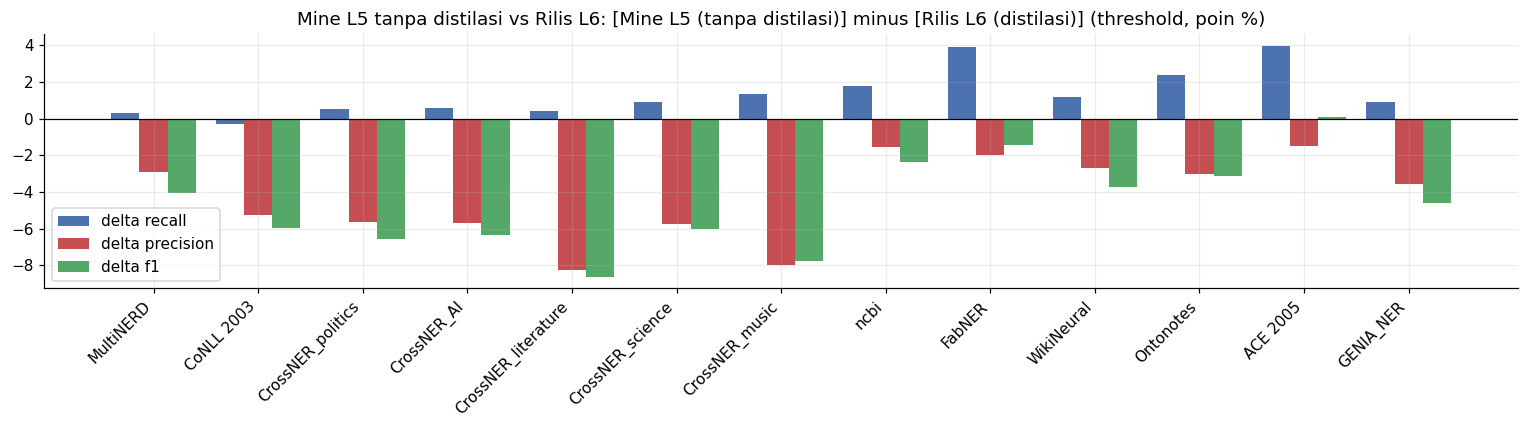

Rata-rata delta: recall +1.37 | precision -4.30 | F1 -4.67 | precision naik di 0/13 dataset


,layer,distilasi,model,recall,precision,f1
0,5,False,Mine L5 (tanpa distilasi),89.62,25.49,38.91
1,5,True,Mine L5 + distilasi,90.73,24.17,37.43
2,6,True,Rilis L6 (distilasi),88.25,29.79,43.58


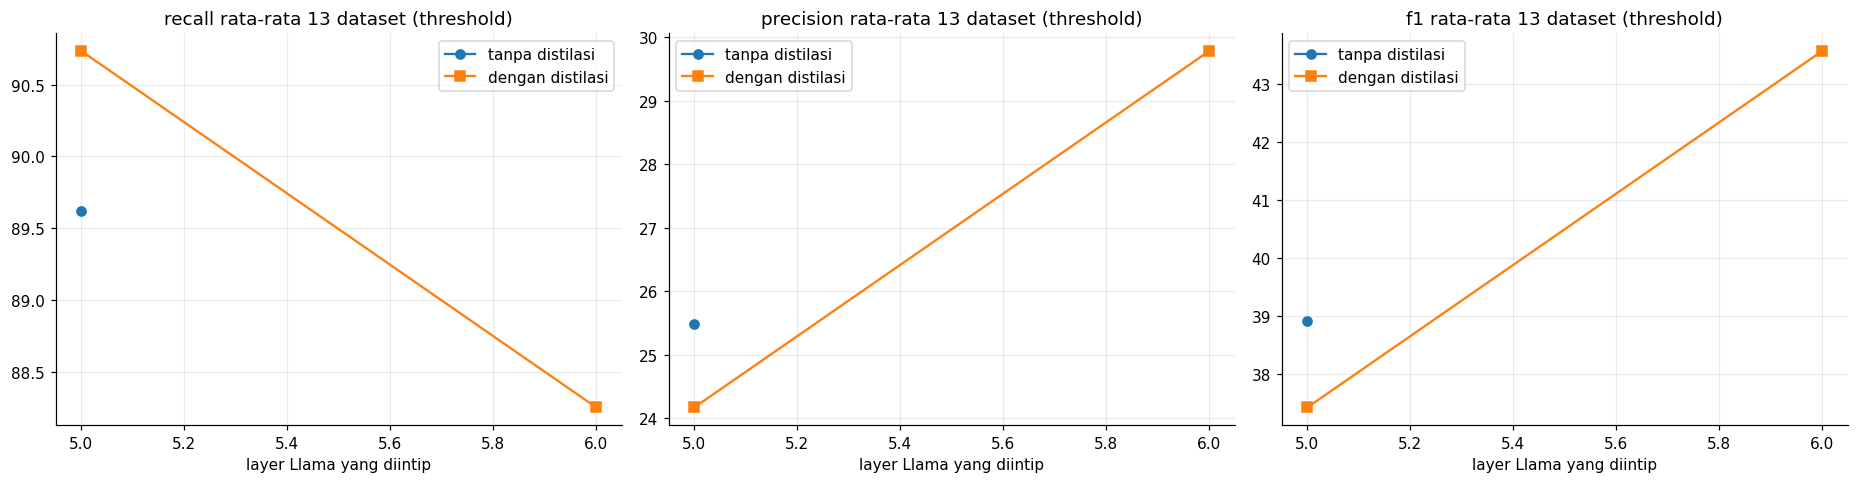

In [21]:
if not R.empty:
    avail = set(R.model.unique())
    PAIRS = [("Mine L5 + distilasi", "Mine L5 (tanpa distilasi)", "Efek DISTILASI di layer 5"),
             ("Mine L3 + distilasi", "Mine L3 (tanpa distilasi)", "Efek DISTILASI di layer 3"),
             ("Mine L3 (tanpa distilasi)", "Mine L5 (tanpa distilasi)", "Efek LAYER 3 vs 5 (tanpa distilasi)"),
             ("Mine L3 + distilasi", "Mine L5 + distilasi", "Efek LAYER 3 vs 5 (dengan distilasi)"),
             ("Mine L5 + distilasi", "Rilis L6 (distilasi)", "Mine L5 + distilasi vs Rilis L6"),
             ("Mine L5 (tanpa distilasi)", "Rilis L6 (distilasi)", "Mine L5 tanpa distilasi vs Rilis L6")]
    done = 0
    for a, b, title in PAIRS:
        if a in avail and b in avail:
            done += 1
            ta, tb = pv("recall", "threshold"), pv("recall", "threshold")
            d = pd.DataFrame({m: pv(m, "threshold")[a] - pv(m, "threshold")[b] for m in ("recall", "precision", "f1")})
            fig, ax = plt.subplots(1, 1, figsize=(14, 4)); x = np.arange(len(d)); w = 0.27
            for j, (c, col) in enumerate(zip(d.columns, ["#4C72B0", "#C44E52", "#55A868"])):
                ax.bar(x + (j - 1) * w, d[c], w, label=f"delta {c}", color=col)
            ax.axhline(0, color="k", lw=0.8); ax.set_xticks(x); ax.set_xticklabels(d.index, rotation=45, ha="right")
            ax.set_title(f"{title}: [{a}] minus [{b}] (threshold, poin %)"); ax.legend(); plt.show()
            print(f"Rata-rata delta: recall {d.recall.mean():+.2f} | precision {d.precision.mean():+.2f} | F1 {d.f1.mean():+.2f} "
                  f"| precision naik di {(d.precision > 0).sum()}/{len(d)} dataset")
    if done == 0:
        print("Pasangan ablasi belum tersedia (butuh minimal dua model yang namanya ada di PAIRS).")

    # efek layer
    pts = []
    for f, (layer, dist) in META.items():
        lab = LABELS.get(f, f)
        g = R[(R.model == lab) & (R.decoding == "threshold") & R.dataset.isin(BENCH)]
        if len(g): pts.append(dict(layer=layer, distilasi=dist, model=lab, recall=g.recall.mean(), precision=g.precision.mean(), f1=g.f1.mean()))
    if len(pts) >= 2:
        P = pd.DataFrame(pts).sort_values(["distilasi", "layer"]); display(P)
        fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
        for a, m in zip(ax, ("recall", "precision", "f1")):
            for dist, mk in ((False, "o-"), (True, "s-")):
                g = P[P.distilasi == dist]
                if len(g): a.plot(g.layer, g[m], mk, label="dengan distilasi" if dist else "tanpa distilasi", lw=1.5)
            a.set_xlabel("layer Llama yang diintip"); a.set_title(f"{m} rata-rata 13 dataset (threshold)"); a.legend()
        plt.show()

### Ciri dataset vs kinerja model (korelasi Pearson, hanya 13 titik: petunjuk, bukan bukti)
Model acuan: Rilis L6 (distilasi)


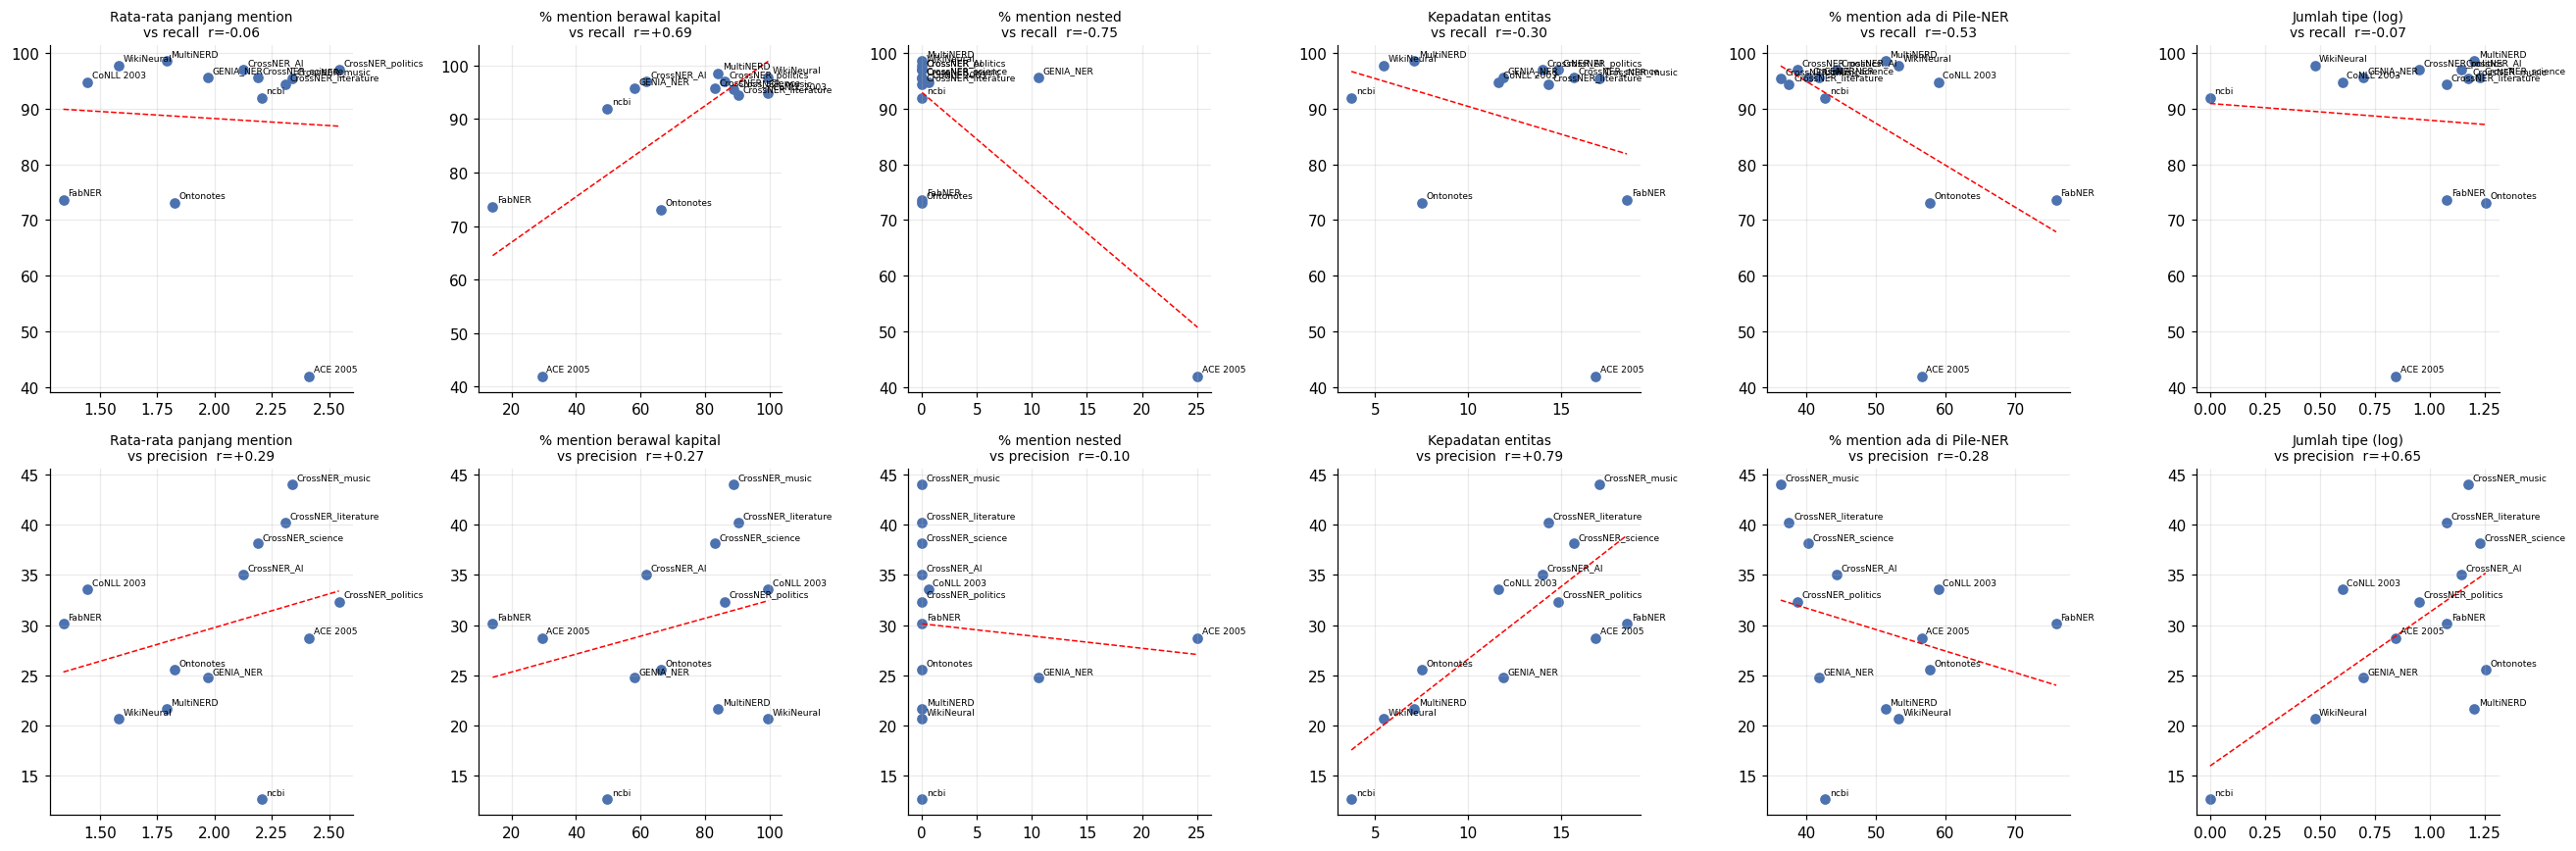

target,precision,recall
fitur,,
% mention ada di Pile-NER,-0.28,-0.53
% mention berawal kapital,0.27,0.69
% mention nested,-0.10,-0.75
Jumlah tipe (log),0.65,-0.07
Kepadatan entitas,0.79,-0.30
Rata-rata panjang mention,0.29,-0.06


Contoh insight yang biasanya muncul: dataset yang mentionnya sering diawali kapital (nama diri) lebih mudah (recall tinggi),
sedangkan ACE 2005 (pronoun, determiner) dan FabNER/Ontonotes (angka, istilah teknis) lebih sulit.


In [22]:
if not R.empty and len(S) > 0:
    print("### Ciri dataset vs kinerja model (korelasi Pearson, hanya 13 titik: petunjuk, bukan bukti)")
    base = "Rilis L6 (distilasi)" if "Rilis L6 (distilasi)" in R.model.unique() else sorted(R.model.unique())[0]
    print("Model acuan:", base)
    t = pd.DataFrame({"recall": pv("recall", "threshold")[base], "precision": pv("precision", "threshold")[base]})
    feat = BF.join(t, how="inner")
    fcols = [("len_mention_rata", "Rata-rata panjang mention"), ("kapital_awal_%", "% mention berawal kapital"),
             ("nested_%", "% mention nested"), ("ent_per_100_kata", "Kepadatan entitas"),
             ("mention_ada_di_PileNER_%", "% mention ada di Pile-NER"), ("n_tipe", "Jumlah tipe (log)")]
    fig, ax = plt.subplots(2, 6, figsize=(24, 8)); corr = []
    for j, (c, title) in enumerate(fcols):
        for i, tgt in enumerate(("recall", "precision")):
            a = ax[i, j]; x = feat[c].astype(float); y = feat[tgt].astype(float)
            if c == "n_tipe": x = np.log10(x.clip(lower=1))
            ok = np.isfinite(x.astype(float)) & np.isfinite(y.astype(float))
            if ok.sum() >= 4 and float(x[ok].std()) > 0 and float(y[ok].std()) > 0:
                r_ = np.corrcoef(x[ok], y[ok])[0, 1]; corr.append({"fitur": title, "target": tgt, "r": r_})
                a.scatter(x[ok], y[ok], color="#4C72B0")
                for n in x[ok].index: a.annotate(n, (x[n], y[n]), fontsize=6, xytext=(3, 3), textcoords="offset points")
                z = np.polyfit(x[ok], y[ok], 1); xs = np.linspace(x[ok].min(), x[ok].max(), 10); a.plot(xs, np.polyval(z, xs), "r--", lw=1)
                a.set_title(f"{title}\nvs {tgt}  r={r_:+.2f}", fontsize=9)
    plt.show()
    if corr: display(pd.DataFrame(corr).pivot(index="fitur", columns="target", values="r"))
    print("Contoh insight yang biasanya muncul: dataset yang mentionnya sering diawali kapital (nama diri) lebih mudah (recall tinggi),")
    print("sedangkan ACE 2005 (pronoun, determiner) dan FabNER/Ontonotes (angka, istilah teknis) lebih sulit.")

## 8. E. Model rilis (`saved_models/`)
Isi folder, konfigurasi, bobot probe, dan **hasil evaluasi penulis paper di CSV rilis**. CSV rilis berisi evaluasi fase 0 (sebelum distilasi)
dan evaluasi akhir (sesudah distilasi), jadi efek distilasi pada layer 6 bisa dilihat langsung tanpa training ulang.

In [23]:
SM = REPO / "saved_models"
if SM.exists():
    for d in sorted(p for p in SM.iterdir() if p.is_dir()):
        print("\n==", d.name)
        for p in sorted(d.iterdir()):
            print(f"   {p.name:55s} {p.stat().st_size/1e3:10.1f} KB")
    rel = SM / "ToMMeR-Llama-3.2-1B_L6_R64"
    if (rel / "README.md").exists():
        print("\n--- README model rilis (3000 karakter pertama) ---")
        print((rel / "README.md").read_text(encoding="utf-8")[:3000])
    if (rel / "experimaestro.json").exists():
        cfg = json.load(open(rel / "experimaestro.json"))
        for o in cfg:
            if o.get("type") == "ToMMeR": print("\nKonfigurasi model rilis:", json.dumps(o["fields"], indent=1))
else:
    print("Folder saved_models tidak ditemukan.")


== Mine-Llama-3.2-1B_L5_R64_distilled
   experimaestro.json                                             0.7 KB
   model.safetensors                                           1057.2 KB

== Mine-Llama-3.2-1B_L5_R64_phase0
   experimaestro.json                                             0.7 KB
   model.safetensors                                           1057.2 KB

== ToMMeR-Llama-3.2-1B_L6_R64
   Eval_0_Flat_threshold(thr=0.5).csv                             1.3 KB
   Eval_1_Flat_greedy(thr=0.5).csv                                1.3 KB
   Eval_1_Nested_threshold(thr=0.5).csv                           0.1 KB
   Eval_2_LLM_Annotated_threshold(thr=0.5).csv                    0.5 KB
   Eval_2_Nested_threshold(thr=0.5).csv                           0.1 KB
   Eval_3_LLM_Annotated_threshold(thr=0.5).csv                    0.5 KB
   Phase0_eval_greedy_0.5.csv                                     2.2 KB
   Phase0_eval_threshold_0.5.csv                                  0.2 KB
   README.md      

In [24]:
WEIGHTS = {}
def load_weights(path):
    try:
        from safetensors.torch import load_file
        return {k: v.float().numpy() for k, v in load_file(str(path)).items()}
    except Exception:
        from safetensors.numpy import load_file
        return load_file(str(path))

if SM.exists():
    for d in sorted(p for p in SM.iterdir() if (p / "model.safetensors").exists()):
        try:
            WEIGHTS[d.name] = load_weights(d / "model.safetensors")
        except Exception as ex:
            print("gagal baca bobot", d.name, repr(ex)); break
if WEIGHTS:
    rows = []
    for n, w in WEIGHTS.items():
        rows.append({"model": n, "n_parameter": sum(v.size for v in w.values()),
                     "norm_W_Q": np.linalg.norm(w["W_Q"]), "norm_W_K": np.linalg.norm(w["W_K"]),
                     "rata_abs_W_Q": np.abs(w["W_Q"]).mean(), "std_fc_weight": w["classifier.fc.weight"].std(),
                     "fc_bias": float(w["classifier.fc.bias"].ravel()[0])})
        for i, v in enumerate(w["cl_w"].ravel()): rows[-1][f"cl_w[{i}]"] = float(v)
    WT = pd.DataFrame(rows).set_index("model"); display(WT)

    NAMES = ["m_ij (skor span)", "max-pool skor dalam", "min-pool skor dalam", "v_j (nilai token akhir)", "v_j+1 (konteks)"]
    fig, ax = plt.subplots(1, 3, figsize=(19, 5)); k = len(WEIGHTS); w_ = 0.8 / max(k, 1)
    for j, (n, w) in enumerate(WEIGHTS.items()):
        ax[0].bar(np.arange(5) + j * w_, w["cl_w"].ravel(), w_, label=n)
        ax[1].hist(w["classifier.fc.weight"].ravel(), bins=60, alpha=0.5, label=n)
    ax[0].set_xticks(np.arange(5) + 0.4); ax[0].set_xticklabels(NAMES, rotation=25, ha="right", fontsize=8)
    ax[0].set_title("Bobot 'cl_w' (5 parameter)\nurutan nama mengikuti Persamaan 2 paper; pemetaan belum diverifikasi di kode"); ax[0].legend(fontsize=6)
    ax[1].set_title("Sebaran bobot classifier.fc (2048 nilai)"); ax[1].legend(fontsize=6)
    ks = list(WEIGHTS)
    M = {n: WEIGHTS[n]["W_Q"] @ WEIGHTS[n]["W_K"].T for n in ks}
    sim = pd.DataFrame([[float((M[a] * M[b]).sum() / (np.linalg.norm(M[a]) * np.linalg.norm(M[b]))) for b in ks] for a in ks], index=ks, columns=ks)
    heat(sim, "Kemiripan bentuk bilinear W_Q W_K^T", ax=ax[2], cmap="coolwarm", fmt="{:.2f}")
    plt.show()
    print("Catatan: kemiripan hanya bermakna antar model dengan LAYER SAMA (ruang representasi berbeda tiap layer).")
else:
    print("Bobot tidak terbaca (safetensors tidak tersedia atau folder kosong).")

gagal baca bobot Mine-Llama-3.2-1B_L5_R64_distilled ModuleNotFoundError("No module named 'safetensors'")
Bobot tidak terbaca (safetensors tidak tersedia atau folder kosong).



### Eval_0_Flat_threshold(thr=0.5).csv


,dataset,precision,recall,f1,true_pos,false_pos,total,total_spans,n_samples,predicted_fraction
0,MultiNERD,0.22,0.99,0.35,"234,608.00","849,008.00","237,990.00","57,489,420.00",154144,0.00
1,CoNLL 2003,0.34,0.95,0.50,"32,955.00","65,261.00","34,766.00","4,686,240.00",16493,0.01
2,CrossNER_politics,0.32,0.97,0.49,"8,569.00","17,901.00","8,831.00","1,450,830.00",1389,0.01
3,CrossNER_AI,0.35,0.97,0.51,"3,666.00","6,799.00","3,778.00","561,540.00",879,0.01
4,CrossNER_literature,0.40,0.94,0.56,"4,492.00","6,665.00","4,757.00","795,870.00",916,0.01
5,CrossNER_science,0.38,0.96,0.55,"6,072.00","9,839.00","6,348.00","1,011,450.00",1193,0.01
6,CrossNER_music,0.44,0.96,0.60,"6,139.00","7,790.00","6,426.00","909,120.00",945,0.01
7,ncbi,0.13,0.92,0.22,"6,266.00","43,267.00","6,816.00","2,257,530.00",3952,0.00
8,FabNER,0.30,0.74,0.43,"47,663.00","110,496.00","64,761.00","6,453,780.00",13681,0.01
9,WikiNeural,0.21,0.98,0.34,"145,776.00","559,402.00","149,003.00","39,091,260.00",92672,0.00



### Eval_1_Flat_greedy(thr=0.5).csv


,dataset,precision,recall,f1,true_pos,false_pos,total,total_spans,n_samples,predicted_fraction
0,MultiNERD,0.30,0.94,0.45,"223,676.00","522,624.00","237,990.00","57,489,420.00",154144,0.00
1,CoNLL 2003,0.45,0.86,0.59,"30,037.00","37,159.00","34,766.00","4,686,240.00",16493,0.01
2,CrossNER_politics,0.55,0.84,0.66,"7,435.00","6,204.00","8,831.00","1,450,830.00",1389,0.01
3,CrossNER_AI,0.51,0.87,0.65,"3,296.00","3,144.00","3,778.00","561,540.00",879,0.01
4,CrossNER_literature,0.57,0.86,0.68,"4,085.00","3,129.00","4,757.00","795,870.00",916,0.01
5,CrossNER_science,0.55,0.86,0.67,"5,454.00","4,446.00","6,348.00","1,011,450.00",1193,0.01
6,CrossNER_music,0.62,0.87,0.72,"5,573.00","3,458.00","6,426.00","909,120.00",945,0.01
7,ncbi,0.17,0.66,0.27,"4,495.00","21,754.00","6,816.00","2,257,530.00",3952,0.00
8,FabNER,0.40,0.49,0.44,"31,745.00","48,271.00","64,761.00","6,453,780.00",13681,0.01
9,WikiNeural,0.28,0.91,0.43,"135,326.00","344,407.00","149,003.00","39,091,260.00",92672,0.00



### Eval_1_Nested_threshold(thr=0.5).csv


,dataset,precision,recall,f1,true_pos,false_pos,total,total_spans,n_samples
0,GENIA_NER,0.25,0.96,0.39,53574,162688,55967,10847880,16563


... (8 outputs left out)


### Phase0_eval_threshold_0.5.csv


,precision,recall,f1,true_pos,false_pos,total,total_spans
CrossNER_science,0.17,0.97,0.29,6419,31695,6622,1096990



### Efek distilasi menurut penulis paper (layer 6): fase 0 vs akhir (threshold, %)


,R_fase0,R_akhir,P_fase0,P_akhir,delta_R,delta_P


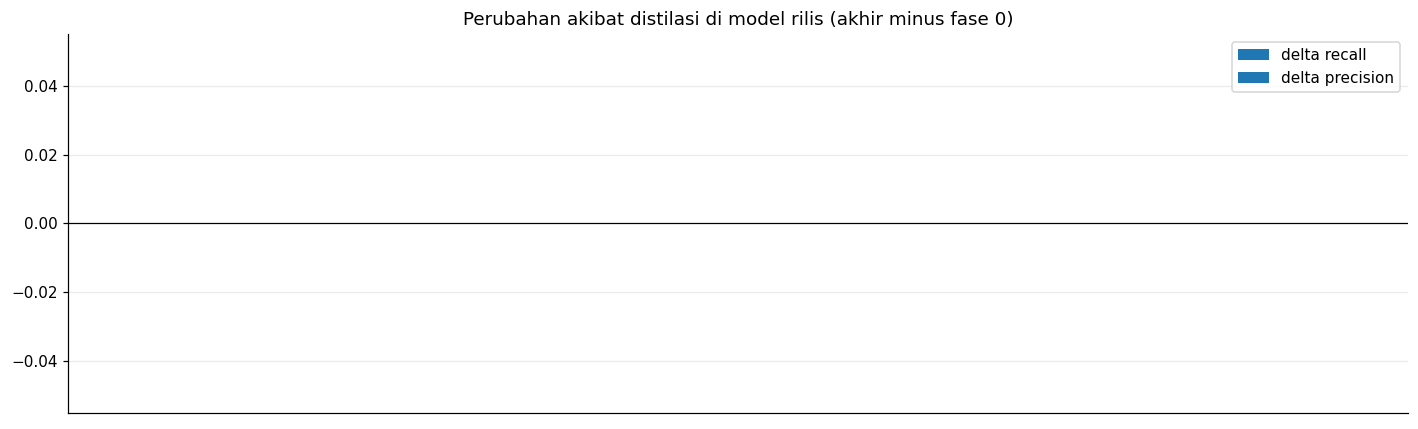

Rata-rata: recall +nan poin | precision +nan poin
Ini patokan: kalau distilasimu (L5) tidak menaikkan precision seperti ini, curigai implementasi atau layer.

### Konsistensi: evaluasimu terhadap model rilis vs CSV rilis (recall, threshold)


,recall_evalmu,recall_CSV_rilis,selisih


In [25]:
def read_rel_csv(p):
    return pd.read_csv(p, sep=None, engine="python", index_col=0)

REL_CSV = {}
if SM.exists() and (SM / "ToMMeR-Llama-3.2-1B_L6_R64").exists():
    for p in sorted((SM / "ToMMeR-Llama-3.2-1B_L6_R64").glob("*.csv")):
        try: REL_CSV[p.name] = read_rel_csv(p)
        except Exception as ex: print("gagal baca", p.name, ex)
    for n, d in REL_CSV.items():
        print(f"\n### {n}"); display(d)
    p0 = next((v for k, v in REL_CSV.items() if k.startswith("Phase0_eval_threshold")), None)
    fin = next((v for k, v in REL_CSV.items() if k.startswith("Eval_0_Flat_threshold") or k.startswith("Eval_0")), None)
    if p0 is not None and fin is not None:
        idx = [i for i in p0.index if i in fin.index]
        d = pd.DataFrame({"R_fase0": 100 * p0.loc[idx, "recall"], "R_akhir": 100 * fin.loc[idx, "recall"],
                          "P_fase0": 100 * p0.loc[idx, "precision"], "P_akhir": 100 * fin.loc[idx, "precision"]})
        d["delta_R"] = d.R_akhir - d.R_fase0; d["delta_P"] = d.P_akhir - d.P_fase0
        print("\n### Efek distilasi menurut penulis paper (layer 6): fase 0 vs akhir (threshold, %)")
        display(d)
        fig, ax = plt.subplots(1, 1, figsize=(13, 4)); x = np.arange(len(d)); w = 0.4
        ax.bar(x - w/2, d.delta_R, w, label="delta recall", color="#4C72B0"); ax.bar(x + w/2, d.delta_P, w, label="delta precision", color="#C44E52")
        ax.axhline(0, color="k", lw=0.8); ax.set_xticks(x); ax.set_xticklabels(d.index, rotation=45, ha="right")
        ax.set_title("Perubahan akibat distilasi di model rilis (akhir minus fase 0)"); ax.legend(); plt.show()
        print(f"Rata-rata: recall {d.delta_R.mean():+.2f} poin | precision {d.delta_P.mean():+.2f} poin")
        print("Ini patokan: kalau distilasimu (L5) tidak menaikkan precision seperti ini, curigai implementasi atau layer.")
    if "results_release.json" and not R.empty and fin is not None:
        a = pv("recall", "threshold").get("Rilis L6 (distilasi)")
        if a is not None:
            ck = pd.DataFrame({"recall_evalmu": a, "recall_CSV_rilis": 100 * fin["recall"]}).dropna()
            ck["selisih"] = ck.recall_evalmu - ck.recall_CSV_rilis
            print("\n### Konsistensi: evaluasimu terhadap model rilis vs CSV rilis (recall, threshold)")
            display(ck)
else:
    print("CSV rilis tidak ditemukan.")

## 9. Ringkasan temuan otomatis
Sel ini menyusun kesimpulan berdasarkan angka yang benar-benar ada. Baca sebagai draf untuk slide, lalu periksa tiap klaim.

In [26]:
L = []
if PILE_ST is not None:
    r = summ_row(PILE_ST)
    L.append(f"Pile-NER: {r['n_sampel']:,} sampel, {r['n_entitas']:,} span, {r['n_tipe']:,} tipe; rata-rata {r['len_mention_rata']:.2f} kata/mention; "
             f"nested hanya {r['nested_%']:.2f}% (label GPT-3.5 hampir tidak memuat entitas bersarang -> alasan distilasi).")
if len(S):
    L.append(f"Benchmark: {int(BF.n_sampel.sum()):,} sampel dan {int(BF.n_entitas.sum()):,} entitas di {len(BF)} dataset "
             f"(paper: 353.250 sampel, 714.143 entitas).")
    hard = BF["kapital_awal_%"].sort_values().index[:2].tolist()
    L.append(f"Dataset dengan mention paling jarang berawal kapital (kandidat sulit): {hard}.")
    if BF["mention_ada_di_PileNER_%"].notna().any():
        mx = BF["mention_ada_di_PileNER_%"].idxmax(); mn = BF["mention_ada_di_PileNER_%"].idxmin()
        L.append(f"Mention benchmark yang juga ada di Pile-NER: tertinggi {mx} ({BF.loc[mx,'mention_ada_di_PileNER_%']:.1f}%), terendah {mn} ({BF.loc[mn,'mention_ada_di_PileNER_%']:.1f}%).")
if not R.empty:
    s = SUM.xs("threshold", level="decoding")
    best = s.f1_macro.idxmax(); bestr = s.recall_macro.idxmax()
    L.append(f"Evaluasi threshold: F1 macro tertinggi = {best} ({s.f1_macro.max():.1f}); recall macro tertinggi = {bestr} ({s.recall_macro.max():.1f}); "
             f"rata-rata recall paper = {PAPER.R_thr.mean():.1f}.")
    for a_, b_, t_ in PAIRS:
        if a_ in avail and b_ in avail:
            dd = pv("precision", "threshold")[a_] - pv("precision", "threshold")[b_]
            rr = pv("recall", "threshold")[a_] - pv("recall", "threshold")[b_]
            L.append(f"{t_}: delta recall {rr.mean():+.2f}, delta precision {dd.mean():+.2f} poin (rata-rata 13 dataset).")
if RUNS:
    sp = [(k, float(np.median(np.diff([s for s, _, _ in v['lr-AdamW']]) / np.maximum(np.diff([w for _, _, w in v['lr-AdamW']]), 1e-9)))) for k, v in RUNS.items() if 'lr-AdamW' in v]
    L.append("Kecepatan training (step/dtk): " + ", ".join(f"{k}={v:.1f}" for k, v in sp) + ".")
display(Markdown("### Ringkasan\n" + "\n".join(f"- {x}" for x in L)))
print("\nKeterbatasan yang perlu ditulis: (1) 13 dataset sedikit untuk korelasi, (2) kata vs token Llama berbeda, "
      "(3) precision terhadap gold bukan precision sebenarnya (paper memakai LLM-judge), (4) satu seed per konfigurasi.")

### Ringkasan
- Pile-NER: 45,889 sampel, 887,917 span, 12,301 tipe; rata-rata 1.66 kata/mention; nested hanya 5.34% (label GPT-3.5 hampir tidak memuat entitas bersarang -> alasan distilasi).
- Benchmark: 421,685 sampel dan 716,019 entitas di 13 dataset (paper: 353.250 sampel, 714.143 entitas).
- Dataset dengan mention paling jarang berawal kapital (kandidat sulit): ['FabNER', 'ACE 2005'].
- Mention benchmark yang juga ada di Pile-NER: tertinggi FabNER (75.9%), terendah CrossNER_music (36.3%).
- Evaluasi threshold: F1 macro tertinggi = Rilis L6 (distilasi) (43.6); recall macro tertinggi = Mine L5 + distilasi (90.7); rata-rata recall paper = 88.2.
- Efek DISTILASI di layer 5: delta recall +1.11, delta precision -1.32 poin (rata-rata 13 dataset).
- Mine L5 + distilasi vs Rilis L6: delta recall +2.48, delta precision -5.62 poin (rata-rata 13 dataset).
- Mine L5 tanpa distilasi vs Rilis L6: delta recall +1.37, delta precision -4.30 poin (rata-rata 13 dataset).


Keterbatasan yang perlu ditulis: (1) 13 dataset sedikit untuk korelasi, (2) kata vs token Llama berbeda, (3) precision terhadap gold bukan precision sebenarnya (paper memakai LLM-judge), (4) satu seed per konfigurasi.
